## Bước 0: môi trường và cấu trúc thư mục

**Làm gì**: tạo môi trường ảo một lần, cài thư viện, tạo thư mục chuẩn. **Vì sao**: cả hai sinh viên và giảng viên chạy cùng phiên bản thư viện thì kết quả tái tạo được; `requirements.txt` là bằng chứng.

**Cấu trúc**: `data/raw` (file gốc, không sửa), `data/processed` (parquet sạch), `sql/` (truy vấn), `report/` (bảng, hình, nhật ký), `notebooks/`.

In [1]:
GROUP = "Nhom 9"
TOPIC = "Hourly Electricity Demand and Grid CO2 Emission Forecasting from EIA-930 Data with Global Gradient Boosting against the Official Day-ahead Forecast on Extreme Days"
UNIT_COL   = "ba"
TIME_COL   = "ts_utc"
TARGET_COL = "demand"
EXOG_COLS  = ["co2_intensity_generated", "co2_intensity_consumed"]
FREQ       = "h"
SEASON     = 24
TEST_START = "2024-07-01"
HORIZONS = [24]
EVENT_QUANTILE = 0.9
TEAL, ACC, GREY = "#1B6B6D", "#F4A261", "#9FBFBF"

def style(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(f"report/{name}.png", dpi=150)
    plt.show()


# ---------------------------------------------------------------------------
# Helper để chú thích biểu đồ: tiêu đề / mô tả nằm PHÍA TRÊN, chú giải (legend) nằm
# NGOÀI vùng vẽ, nhận xét nằm PHÍA DƯỚI  -> chữ không bao giờ đè lên dữ liệu.
# ---------------------------------------------------------------------------
import textwrap, math
from matplotlib.ticker import FuncFormatter

fmt_k = FuncFormatter(lambda v, _: f"{v/1000:,.0f}k" if abs(v) >= 1000 else f"{v:,.0f}")   # 20000 -> 20k
fmt_int = FuncFormatter(lambda v, _: f"{v:,.0f}")                                          # 8000 -> 8,000
fmt_pct = FuncFormatter(lambda v, _: f"{v:.0%}")                                           # 0.5 -> 50%

def _wrap(text, width):
    return "\n".join(textwrap.fill(p, width) for p in text.split("\n"))

def annotate_fig(fig, title, subtitle=None, caption=None, legend_from=None, legend_ncol=4):
    """Thêm tiêu đề, mô tả, legend (ngoài trục) và khung nhận xét (dưới cùng) cho một figure."""
    w, h0 = fig.get_size_inches()
    t_txt = _wrap(title, max(28, int(w * 8.2)))
    s_txt = _wrap(subtitle, int(w * 12)) if subtitle else ""
    c_txt = _wrap(caption, int(w * 12.5)) if caption else ""
    n_t, n_s, n_c = t_txt.count("\n") + 1, (s_txt.count("\n") + 1 if s_txt else 0), (c_txt.count("\n") + 1 if c_txt else 0)

    handles, labels = [], []
    if legend_from is not None:
        handles, labels = legend_from.get_legend_handles_labels()

    # bố cục theo inch, tính từ mép trên xuống
    y = 0.10
    y_title = y;                       y += 0.23 * n_t + 0.04
    y_sub = y;                         y += (0.16 * n_s + 0.08) if n_s else 0
    y_leg = y
    if handles:
        ncol = min(legend_ncol, len(handles))
        y += 0.25 * math.ceil(len(handles) / ncol) + 0.06
    top_in = y + 0.05
    bot_in = (0.34 + 0.165 * n_c) if n_c else 0.05

    H = h0 + top_in + bot_in
    fig.set_size_inches(w, H)
    fy = lambda inch_from_top: 1 - inch_from_top / H

    fig.text(0.5, fy(y_title), t_txt, ha="center", va="top", fontsize=12.5, fontweight="bold", linespacing=1.2)
    if s_txt:
        fig.text(0.5, fy(y_sub), s_txt, ha="center", va="top", fontsize=9.5, color="#444444", linespacing=1.3)
    if handles:
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, fy(y_leg)),
                   ncol=ncol, frameon=False, fontsize=9)
    if c_txt:
        fig.text(0.015, 0.10 / H, c_txt, ha="left", va="bottom", fontsize=9, color="#222222", linespacing=1.35,
                 bbox=dict(boxstyle="round,pad=0.45", fc="#F3F7F7", ec="#CFE0E0"))
    fig.tight_layout(rect=(0, bot_in / H, 1, 1 - top_in / H))

def savefig_annotated(fig, name, title, subtitle=None, caption=None, legend_from=None, legend_ncol=4, dpi=150):
    annotate_fig(fig, title, subtitle, caption, legend_from, legend_ncol)
    fig.savefig(f"report/{name}.png", dpi=dpi)
    plt.show()


In [2]:
# Step 0a: run once in a terminal (not in the notebook)
# python -m venv .venv && .\.venv\Scripts\Activate.ps1
# pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost catboost statsmodels shap matplotlib seaborn ydata-profiling mapie jupyter
# pip freeze > requirements.txt
import os
for d in ["data","data/raw", "data/processed", "sql", "report", "src", "notebooks"]: os.makedirs(d, exist_ok=True)
print("folders ready")

folders ready


In [3]:
# Environment check and shared imports for the whole notebook
import pandas as pd, numpy as np, duckdb, matplotlib
import matplotlib.pyplot as plt, pathlib, warnings
warnings.filterwarnings('ignore')
for d in ['data/raw', 'data/processed', 'notebooks', 'sql', 'src', 'report']: pathlib.Path(d).mkdir(parents=True, exist_ok=True)
np.random.seed(42); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
print('pandas', pd.__version__, '| duckdb', duckdb.__version__)

pandas 2.3.3 | duckdb 1.5.5


In [4]:
# Đọc dữ liệu
file_path = "data/raw/EIA930_BALANCE_2022_2024.csv"
df = pd.read_csv(file_path)
print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")

Number of rows    : 1,626,431
Number of columns : 74


In [5]:
# kiểm tra thông tin dữ liệu

print(df.info())  # Kiểm tra kiểu dữ liệu
print(df.isnull().sum())  # Kiểm tra giá trị thiếu

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1626431 entries, 0 to 1626430
Data columns (total 74 columns):
 #   Column                                                                        Non-Null Count    Dtype  
---  ------                                                                        --------------    -----  
 0   Balancing Authority                                                           1626431 non-null  object 
 1   Data Date                                                                     1626431 non-null  object 
 2   Hour Number                                                                   1626431 non-null  int64  
 3   Local Time at End of Hour                                                     1626431 non-null  object 
 4   UTC Time at End of Hour                                                       1626431 non-null  object 
 5   Demand Forecast (MW)                                                          1387972 non-null  float64
 6   Demand (MW

In [6]:
df.head() #đọc 5 dòng đầu tiên của dữ liệu

,Balancing Authority,Data Date,Hour Number,Local Time at End of Hour,UTC Time at End of Hour,Demand Forecast (MW),Demand (MW),Net Generation (MW),Total Interchange (MW),Sum(Valid DIBAs) (MW),Demand (MW) (Imputed),Net Generation (MW) (Imputed),Total Interchange (MW) (Imputed),Demand (MW) (Adjusted),Net Generation (MW) (Adjusted),Total Interchange (MW) (Adjusted),Net Generation (MW) from Coal,Net Generation (MW) from Natural Gas,Net Generation (MW) from Nuclear,Net Generation (MW) from All Petroleum Products,...,Net Generation (MW) from Hydropower Excluding Pumped Storage (Imputed),Net Generation (MW) from Pumped Storage (Imputed),Net Generation (MW) from Solar without Integrated Battery Storage (Imputed),Net Generation (MW) from Solar with Integrated Battery Storage (Imputed),Net Generation (MW) from Wind without Integrated Battery Storage (Imputed),Net Generation (MW) from Wind with Integrated Battery Storage (Imputed),Net Generation (MW) from Battery Storage (Imputed),Net Generation (MW) from Other Energy Storage (Imputed),Net Generation (MW) from Unknown Energy Storage (Imputed),Net Generation (MW) from Geothermal (Imputed),Net Generation (MW) from Hydropower Excluding Pumped Storage (Adjusted),Net Generation (MW) from Pumped Storage (Adjusted),Net Generation (MW) from Solar without Integrated Battery Storage (Adjusted),Net Generation (MW) from Solar witho Integrated Battery Storage (Adjusted),Net Generation (MW) from Wind without Integrated Battery Storage (Adjusted),Net Generation (MW) from Wind with Integrated Battery Storage (Adjusted),Net Generation (MW) from Battery Storage (Adjusted),Net Generation (MW) from Other Energy Storage (Adjusted),Net Generation (MW) from Unknown Energy Storage (Adjusted),Net Generation (MW) from Geothermal (Adjusted)
0,AECI,01/01/2022,1,01/01/2022 1:00:00 AM,2022-01-01 07:00:00,2235.0,2251.0,1986.0,-265.0,-265.0,NaN,NaN,NaN,2251.0,1986.0,-265.0,996.0,299.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AECI,01/01/2022,2,01/01/2022 2:00:00 AM,2022-01-01 08:00:00,2217.0,2208.0,2039.0,-169.0,-169.0,NaN,NaN,NaN,2208.0,2039.0,-169.0,941.0,302.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AECI,01/01/2022,3,01/01/2022 3:00:00 AM,2022-01-01 09:00:00,2193.0,2204.0,2080.0,-124.0,-124.0,NaN,NaN,NaN,2204.0,2080.0,-124.0,951.0,369.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AECI,01/01/2022,4,01/01/2022 4:00:00 AM,2022-01-01 10:00:00,2255.0,2234.0,2110.0,-124.0,-124.0,NaN,NaN,NaN,2234.0,2110.0,-124.0,957.0,386.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AECI,01/01/2022,5,01/01/2022 5:00:00 AM,2022-01-01 11:00:00,2325.0,2287.0,2138.0,-149.0,-149.0,NaN,NaN,NaN,2287.0,2138.0,-149.0,992.0,405.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## RQ1 - Bước 1: Đăng ký nguồn dữ liệu vào sổ nguồn

**Làm gì**: đăng ký hai nguồn (chính và phụ) vào sổ nguồn (`report/data_sources.csv`) với URL, giấy phép, ngày tải, số dòng.

**Vì sao**: phần Data của bài báo cần ghi rõ nguồn là công trình nào, năm nào, số dòng, số cột và lý do chọn; sổ nguồn giúp viết phần đó trong hai phút.

In [7]:
# Sổ nguồn dữ liệu (data source log) cho RQ1
import pandas as pd, os
from datetime import datetime

# TODO: thay url bằng đường dẫn tải chính xác bạn đã dùng (thường là link export của EIA-930 Grid Monitor)
sources_info = [
    {
        "source_id": "primary_balance",
        "role": "Nguon chinh (primary)",
        "name": "EIA-930 Balance file - demand/generation/interchange theo tung Balancing Authority",
        "file_path": "data/raw/EIA930_BALANCE_2022_2024.csv",
        "url": "https://www.eia.gov/electricity/gridmonitor/dashboard/electric_overview/US48/US48",
        "license": "Public domain - U.S. Government work (EIA)",
        "coverage": "2022-01-01 to 2024-12-31, tat ca BA cua US48",
        "date_accessed": datetime.today().strftime("%Y-%m-%d"),
    },
    {
        "source_id": "secondary_8ba",
        "role": "Nguon phu (secondary)",
        "name": "EIA-930 8BA detailed file - them CO2 emission factors/intensity cho mot nhom BA",
        "file_path": "data/raw/EIA930_8BA_2022_2025.csv",
        "url": "https://www.eia.gov/electricity/gridmonitor/dashboard/electric_overview/US48/US48",
        "license": "Public domain - U.S. Government work (EIA)",
        "coverage": "2022-01-01 to 2025-..., mot nhom BA co them thong tin CO2",
        "date_accessed": datetime.today().strftime("%Y-%m-%d"),
    },
]

def count_rows_cols(path):
    """Dem so dong/cot bang cach doc theo dong, tranh load ca file lon vao RAM hai lan."""
    if not os.path.exists(path):
        return None, None, None
    with open(path, encoding="utf-8", errors="ignore") as f:
        header = f.readline()
        n_cols = len(header.strip().split(","))
        n_rows = sum(1 for _ in f)
    size_mb = round(os.path.getsize(path) / (1024**2), 2)
    return n_rows, n_cols, size_mb

rows = []
for s in sources_info:
    n_rows, n_cols, size_mb = count_rows_cols(s["file_path"])
    rows.append({**s, "n_rows": n_rows, "n_cols": n_cols, "file_size_mb": size_mb})

log_df = pd.DataFrame(rows)

os.makedirs("report", exist_ok=True)
log_path = "report/data_sources.csv"
log_df.to_csv(log_path, index=False, encoding="utf-8-sig")

print(f"Da ghi so nguon vao: {log_path}")
log_df

Da ghi so nguon vao: report/data_sources.csv


,source_id,role,name,file_path,url,license,coverage,date_accessed,n_rows,n_cols,file_size_mb
0,primary_balance,Nguon chinh (primary),EIA-930 Balance file - demand/generation/inter...,data/raw/EIA930_BALANCE_2022_2024.csv,https://www.eia.gov/electricity/gridmonitor/da...,Public domain - U.S. Government work (EIA),"2022-01-01 to 2024-12-31, tat ca BA cua US48",2026-09-30,1626431,74,338.51
1,secondary_8ba,Nguon phu (secondary),EIA-930 8BA detailed file - them CO2 emission ...,data/raw/EIA930_8BA_2022_2025.csv,https://www.eia.gov/electricity/gridmonitor/da...,Public domain - U.S. Government work (EIA),"2022-01-01 to 2025-..., mot nhom BA co them th...",2026-09-30,210456,118,109.80


## RQ1 - Bước 2: Đối chiếu nhất quán giữa hai nguồn

**Làm gì**: ghép nguồn chính (BALANCE) và nguồn phụ (8BA) theo cặp (đơn vị BA, giờ UTC), rồi so Demand / Net Generation / Total Interchange giữa hai bên bằng tương quan, độ lệch trung bình (bias) và sai số tuyệt đối trung bình (MAE).

**Vì sao**: nếu hai nguồn lệch nhau nhiều (bias lớn hoặc tương quan thấp), phải nêu rõ trong phần Data và quyết định nguồn nào là "sự thật" cho biến mục tiêu, trước khi ghép đặc trưng phụ vào mô hình.

**Cách làm**: dùng `duckdb` để đọc thẳng hai file CSV lớn (không nạp hết vào RAM qua pandas), ghép bằng SQL, rồi mới lấy phần tổng hợp ra pandas để xem/lưu.

In [8]:
# Tao view DuckDB cho hai nguon, chuan hoa ten cot va kieu thoi gian ve cung mot dang
import duckdb

con = duckdb.connect()

con.execute("""
    CREATE OR REPLACE VIEW primary_src AS
    SELECT
        "Balancing Authority"                  AS ba,
        CAST("UTC Time at End of Hour" AS TIMESTAMP) AS ts_utc,
        "Demand (MW)"                          AS demand_primary,
        "Net Generation (MW)"                  AS gen_primary,
        "Total Interchange (MW)"               AS interchange_primary
    FROM read_csv_auto('data/raw/EIA930_BALANCE_2022_2024.csv', SAMPLE_SIZE=-1)
""")

con.execute("""
    CREATE OR REPLACE VIEW secondary_src AS
    SELECT
        "BA"                                   AS ba,
        CAST("UTC time" AS TIMESTAMP)          AS ts_utc,
        "Demand"                                AS demand_secondary,
        "Net generation"                        AS gen_secondary,
        "Total interchange"                     AS interchange_secondary
    FROM read_csv_auto('data/raw/EIA930_8BA_2022_2025.csv', SAMPLE_SIZE=-1)
""")

# Cac don vi (BA) xuat hien o CA HAI nguon - chi so nay moi doi chieu duoc
common_ba = con.execute("""
    SELECT p.ba
    FROM (SELECT DISTINCT ba FROM primary_src)   p
    INNER JOIN (SELECT DISTINCT ba FROM secondary_src) s USING (ba)
    ORDER BY p.ba
""").df()

# Kiem tra quy mo cua tung nguon truoc khi ket luan ve "tinh nhat quan":
# neu chi mot phan nho BA cua nguon phu khop voi nguon chinh, ket luan chi ap dung
# cho nhom BA do, khong suy rong ra toan bo US48.
n_ba_primary = con.execute("SELECT COUNT(DISTINCT ba) FROM primary_src").df().iloc[0, 0]
n_ba_secondary = con.execute("SELECT COUNT(DISTINCT ba) FROM secondary_src").df().iloc[0, 0]

print(f"So BA co trong nguon chinh (BALANCE)   : {n_ba_primary}")
print(f"So BA co trong nguon phu (8BA)         : {n_ba_secondary}")
print(f"So BA xuat hien o CA HAI nguon         : {len(common_ba)}")
print(common_ba["ba"].tolist())

if len(common_ba) < 0.5 * n_ba_secondary:
    print("\nCANH BAO: it hon 50% so BA cua nguon phu khop ten voi nguon chinh.")
    print("Kiem tra lai xem co ky hieu BA nao bi viet khac nhau giua 2 file khong")
    print("(vi du PACE/PACW, hoac BA bi gop/tach thanh subregion o file 8BA).")


So BA co trong nguon chinh (BALANCE)   : 63
So BA co trong nguon phu (8BA)         : 8
So BA xuat hien o CA HAI nguon         : 8
['AZPS', 'BPAT', 'CISO', 'LDWP', 'NEVP', 'PACW', 'PGE', 'SRP']


In [9]:
# Doi chieu nguon chinh vs nguon phu cho Demand, Net Generation, Total Interchange:
# tinh corr, bias, MAE, RMSE, MAPE - CA o muc TONG THE va THEO TUNG BA trong 1 khoi duy nhat
# (gop lai de tranh tinh trung lap voi khoi RQ1a phia duoi).
shared_vars = {
    "Demand":            ("demand_primary", "demand_secondary"),
    "Net Generation":    ("gen_primary", "gen_secondary"),
    "Total Interchange": ("interchange_primary", "interchange_secondary"),
}

overall_rows = []
per_ba_frames = []

for var_name, (col_p, col_s) in shared_vars.items():
    # --- Tong the (tat ca BA chung gop lai) ---
    stat = con.execute(f"""
        WITH joined AS (
            SELECT p.{col_p} AS v_p, s.{col_s} AS v_s
            FROM primary_src p
            INNER JOIN secondary_src s ON p.ba = s.ba AND p.ts_utc = s.ts_utc
            WHERE p.{col_p} IS NOT NULL AND s.{col_s} IS NOT NULL
        )
        SELECT
            count(*)                                          AS n_matched,
            corr(v_p, v_s)                                     AS corr,
            avg(v_p - v_s)                                     AS bias,
            avg(abs(v_p - v_s))                                AS mae,
            sqrt(avg((v_p - v_s) * (v_p - v_s)))               AS rmse,
            avg(abs(v_p - v_s) / NULLIF(abs(v_p), 0)) * 100    AS mape_pct
        FROM joined
    """).df().iloc[0]
    overall_rows.append({"variable": var_name, **stat.to_dict()})

    # --- Theo tung BA ---
    per_ba = con.execute(f"""
        WITH joined AS (
            SELECT p.ba, p.{col_p} AS v_p, s.{col_s} AS v_s
            FROM primary_src p
            INNER JOIN secondary_src s ON p.ba = s.ba AND p.ts_utc = s.ts_utc
            WHERE p.{col_p} IS NOT NULL AND s.{col_s} IS NOT NULL
        )
        SELECT
            ba,
            count(*)                                          AS n_matched,
            corr(v_p, v_s)                                     AS corr,
            avg(v_p - v_s)                                     AS bias,
            avg(abs(v_p - v_s))                                AS mae,
            avg(abs(v_p - v_s) / NULLIF(abs(v_p), 0)) * 100    AS mape_pct
        FROM joined
        GROUP BY ba
        ORDER BY mae DESC
    """).df()
    per_ba.insert(0, "variable", var_name)
    per_ba_frames.append(per_ba)

var_compare = pd.DataFrame(overall_rows)
per_ba_stats = pd.concat(per_ba_frames, ignore_index=True)

print("Doi chieu TONG THE (tat ca BA chung), theo tung bien:")
display(var_compare)

print("\nTop 10 dong lech nhieu nhat (theo tung BA, tung bien):")
display(per_ba_stats.head(10))

import os
os.makedirs("report", exist_ok=True)
var_compare.to_csv("report/rq1a_source_comparison_by_variable.csv", index=False, encoding="utf-8-sig")
per_ba_stats.to_csv("report/rq1_consistency_by_ba.csv", index=False, encoding="utf-8-sig")
print("\nDa luu report/rq1a_source_comparison_by_variable.csv va report/rq1_consistency_by_ba.csv")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Doi chieu TONG THE (tat ca BA chung), theo tung bien:


,variable,n_matched,corr,bias,mae,rmse,mape_pct
0,Demand,210281.0,1.0,0.0,0.0,0.0,0.0
1,Net Generation,210282.0,1.0,0.0,0.0,0.0,0.0
2,Total Interchange,208004.0,1.0,0.0,0.0,0.0,0.0



Top 10 dong lech nhieu nhat (theo tung BA, tung bien):


,variable,ba,n_matched,corr,bias,mae,mape_pct
0,Demand,SRP,26255,1.0,0.0,0.0,0.0
1,Demand,LDWP,26255,1.0,0.0,0.0,0.0
2,Demand,NEVP,26304,1.0,0.0,0.0,0.0
3,Demand,AZPS,26304,1.0,0.0,0.0,0.0
4,Demand,PACW,26304,1.0,0.0,0.0,0.0
5,Demand,BPAT,26304,1.0,0.0,0.0,0.0
6,Demand,PGE,26304,1.0,0.0,0.0,0.0
7,Demand,CISO,26251,1.0,0.0,0.0,0.0
8,Net Generation,SRP,26256,1.0,0.0,0.0,0.0
9,Net Generation,PGE,26304,1.0,0.0,0.0,0.0



Da luu report/rq1a_source_comparison_by_variable.csv va report/rq1_consistency_by_ba.csv


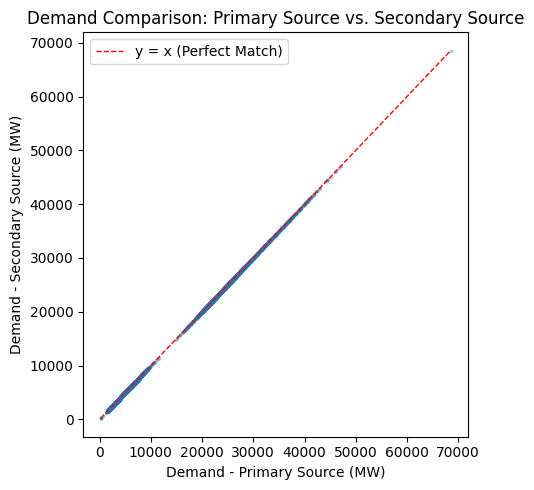

In [41]:
# Ve scatter Demand nguon chinh vs nguon phu (lay mau de ve nhanh voi du lieu lon)
sample = con.execute("""
    SELECT p.demand_primary, s.demand_secondary
    FROM primary_src p
    INNER JOIN secondary_src s
        ON p.ba = s.ba AND p.ts_utc = s.ts_utc
    WHERE p.demand_primary IS NOT NULL AND s.demand_secondary IS NOT NULL
    USING SAMPLE 20000
""").df()

lo = sample[["demand_primary", "demand_secondary"]].min().min()
hi = sample[["demand_primary", "demand_secondary"]].max().max()

plt.figure(figsize=(5, 5))
plt.scatter(sample["demand_primary"], sample["demand_secondary"], s=3, alpha=0.3)
plt.plot([lo, hi], [lo, hi], "r--", linewidth=1, label="y = x (Perfect Match)")
plt.xlabel("Demand - Primary Source (MW)")
plt.ylabel("Demand - Secondary Source (MW)")
plt.title("Demand Comparison: Primary Source vs. Secondary Source")
plt.legend()
plt.tight_layout()
plt.savefig("report/rq1_consistency_scatter.png", dpi=150)
plt.show()

**Cách đọc kết quả**:
- `corr_demand` gần 1 và `bias_mw` gần 0 → hai nguồn nhất quán, có thể dùng thay thế/bổ sung cho nhau.
- `bias_mw` lệch hệ thống (luôn dương hoặc luôn âm) → khả năng khác định nghĩa (ví dụ giờ local vs UTC lệch múi giờ, hoặc một bên đã impute/adjust còn bên kia chưa) — cần kiểm tra lại bước chuẩn hoá cột.
- `mae_mw` / `mape_pct` cao bất thường ở một vài BA cụ thể trong `report/rq1_consistency_by_ba.csv` → nêu rõ trong phần Data là những BA này nguồn phụ không đáng tin, cân nhắc loại khỏi phân tích dùng nguồn phụ.

**So sánh nguồn (RQ1a)**: trước khi ghép, đo (1) khoảng thời gian chồng nhau, (2) tỷ lệ bước thời gian có ở nguồn này mà không có ở nguồn kia, (3) nếu hai nguồn có cùng một biến thì tương quan và độ lệch trung bình, (4) độ trễ cập nhật (thời điểm cuối của mỗi nguồn). Bảng này vào phần Data của bài.

In [11]:
# RQ1a - (1) khoang chong nhau va (4) do tre cap nhat (dua tren cac view da tao o Buoc 2)
range_stats = con.execute("""
    SELECT
        (SELECT min(ts_utc) FROM primary_src)   AS p_min,
        (SELECT max(ts_utc) FROM primary_src)   AS p_max,
        (SELECT min(ts_utc) FROM secondary_src) AS s_min,
        (SELECT max(ts_utc) FROM secondary_src) AS s_max
""").df().iloc[0]

overlap_start = max(range_stats["p_min"], range_stats["s_min"])
overlap_end   = min(range_stats["p_max"], range_stats["s_max"])
update_lag_days = (range_stats["p_max"] - range_stats["s_max"]).days  # duong = nguon chinh moi hon nguon phu

print(f"Nguon chinh   : {range_stats['p_min']} -> {range_stats['p_max']}")
print(f"Nguon phu     : {range_stats['s_min']} -> {range_stats['s_max']}")
print(f"Khoang chong  : {overlap_start} -> {overlap_end}")
print(f"Do tre cap nhat (nguon chinh tru nguon phu): {update_lag_days} ngay")

# RQ1a - (2) ty le buoc thoi gian lech nhau, chi tinh trong pham vi cac BA chung + khoang chong nhau
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE p_ts AS
    SELECT DISTINCT ba, ts_utc FROM primary_src
    WHERE ba IN (SELECT ba FROM common_ba) AND ts_utc BETWEEN '{overlap_start}' AND '{overlap_end}'
""")
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE s_ts AS
    SELECT DISTINCT ba, ts_utc FROM secondary_src
    WHERE ba IN (SELECT ba FROM common_ba) AND ts_utc BETWEEN '{overlap_start}' AND '{overlap_end}'
""")

coverage_gap = con.execute("""
    SELECT
        (SELECT count(*) FROM p_ts) AS n_primary,
        (SELECT count(*) FROM s_ts) AS n_secondary,
        (SELECT count(*) FROM (SELECT * FROM p_ts EXCEPT SELECT * FROM s_ts)) AS in_primary_only,
        (SELECT count(*) FROM (SELECT * FROM s_ts EXCEPT SELECT * FROM p_ts)) AS in_secondary_only
""").df().iloc[0]

pct_primary_only = 100 * coverage_gap["in_primary_only"] / coverage_gap["n_primary"]
pct_secondary_only = 100 * coverage_gap["in_secondary_only"] / coverage_gap["n_secondary"]

print(f"\n% buoc thoi gian co o nguon chinh nhung khong co o nguon phu: {pct_primary_only:.2f}%")
print(f"% buoc thoi gian co o nguon phu nhung khong co o nguon chinh: {pct_secondary_only:.2f}%")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Nguon chinh   : 2022-01-01 06:00:00 -> 2025-01-01 08:00:00
Nguon phu     : 2022-01-01 06:00:00 -> 2025-01-01 08:00:00
Khoang chong  : 2022-01-01 06:00:00 -> 2025-01-01 08:00:00
Do tre cap nhat (nguon chinh tru nguon phu): 0 ngay

% buoc thoi gian co o nguon chinh nhung khong co o nguon phu: 0.00%
% buoc thoi gian co o nguon phu nhung khong co o nguon chinh: 0.01%


In [12]:
# Gop toan bo cac chi so RQ1a (khoang chong, coverage gap, do tre cap nhat, so BA chung)
# thanh MOT bang tom tat cho phan Data cua bai.
# LUU Y: khong tinh lai corr/bias/mae o day nua - da co du trong bang var_compare o Buoc 2 (Cell truoc),
# tranh code trung lap va so lieu co the lech nhau giua 2 noi neu sua sau nay.
source_comparison_summary = pd.DataFrame([{
    "primary_range_start": range_stats["p_min"], "primary_range_end": range_stats["p_max"],
    "secondary_range_start": range_stats["s_min"], "secondary_range_end": range_stats["s_max"],
    "overlap_start": overlap_start, "overlap_end": overlap_end,
    "update_lag_days_primary_minus_secondary": update_lag_days,
    "pct_timesteps_primary_only": round(pct_primary_only, 3),
    "pct_timesteps_secondary_only": round(pct_secondary_only, 3),
    "n_ba_primary": n_ba_primary,
    "n_ba_secondary": n_ba_secondary,
    "n_common_ba": len(common_ba),
}])

import os
os.makedirs("report", exist_ok=True)
source_comparison_summary.to_csv("report/rq1a_source_comparison_summary.csv", index=False, encoding="utf-8-sig")
print("Da luu report/rq1a_source_comparison_summary.csv")
print("\n(Bang tuong quan/bias/mae theo tung bien nam trong report/rq1a_source_comparison_by_variable.csv,")
print(" bang chi tiet theo tung BA nam trong report/rq1_consistency_by_ba.csv - da luu o Buoc 2.)")
source_comparison_summary


Da luu report/rq1a_source_comparison_summary.csv

(Bang tuong quan/bias/mae theo tung bien nam trong report/rq1a_source_comparison_by_variable.csv,
 bang chi tiet theo tung BA nam trong report/rq1_consistency_by_ba.csv - da luu o Buoc 2.)


,primary_range_start,primary_range_end,secondary_range_start,secondary_range_end,overlap_start,overlap_end,update_lag_days_primary_minus_secondary,pct_timesteps_primary_only,pct_timesteps_secondary_only,n_ba_primary,n_ba_secondary,n_common_ba
0,2022-01-01 06:00:00,2025-01-01 08:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,0,0.0,0.011,63,8,8


## Luu y ve vai tro cua bien CO2 trong nguon phu (8BA) cho phan con lai cua RQ1

Cac cot CO2 Emissions / CO2 Emissions Intensity trong file 8BA la **ket qua tinh tu co cau nguon phat (generation mix)**,
khong phai mot bien ngoai sinh doc lap kieu thoi tiet. Vi vay khi lam tiep phan RQ1 con lai
("phan nao bien dong duoc giai thich bang lich so voi bang nguon phu"), can phan biet ro hai vai tro:

- **Dung 8BA de kiem tra tinh nhat quan giua hai nguon** (Demand, Net Generation, Total Interchange) - day chinh la phan da lam o tren, hop ly va giu nguyen.
- **KHONG nen** dua truc tiep CO2 Emissions Intensity vao `EXOG_COLS` de "giai thich" bien dong cua Demand,
  vi chieu nhan qua la Demand -> generation mix -> CO2, khong phai nguoc lai; dua vao se gay hieu nham ve nguyen nhan.
- Nen coi **CO2 emissions la mot target/bien phan tich phu**, dung voi ten de tai
  ("... and Grid CO2 Emission Forecasting"): phan tich bien dong CO2 theo mua, theo BA, tuong tu nhu voi Demand,
  thay vi dung no lam covariate du bao Demand.
- Neu van muon co mot bien ngoai sinh thuc su (theo dung y `SECOND_SOURCE` ban dau cua Notebook_C la thoi tiet),
  can bo sung nguon thoi tiet (VD NOAA ISD hourly) hoac dung ty trong fuel-mix (% nang luong tai tao / % than / % khi)
  tinh tu chinh file BALANCE lam covariate cho Demand, thay vi dung CO2 intensity.

In [13]:
#Tạo bảng làm việc từ nguồn chính + nhật ký làm sạch rỗng
final_df = con.execute("SELECT ba, ts_utc, demand_primary AS demand FROM primary_src").df()
df = final_df.copy()
clean_log = []  # moi phan tu: [ten buoc, so dong truoc, so dong sau, so dong bi loai, ly do]
print(f"Bat dau: {len(df):,} dong, {df['ba'].nunique()} BA")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Bat dau: 1,626,431 dong, 63 BA


In [14]:
#Bỏ dòng không đọc được thời gian
n_before = len(df)
df = df.dropna(subset=["ts_utc"])
n_after = len(df)
clean_log.append(["parse time", n_before, n_after, n_before - n_after, "khong doc duoc timestamp"])
print(f"parse time: {n_before:,} -> {n_after:,}")

parse time: 1,626,431 -> 1,626,431


In [15]:
#Khử trùng lặp theo (BA, giờ UTC)
n_before = len(df)
df = df.drop_duplicates(subset=["ba", "ts_utc"])
n_after = len(df)
clean_log.append(["drop duplicates", n_before, n_after, n_before - n_after, "trung ba + thoi diem"])
print(f"drop duplicates: {n_before:,} -> {n_after:,}")

drop duplicates: 1,626,431 -> 1,626,431


In [16]:
#Ép kiểu số cho target + bỏ dòng thiếu target
df["demand"] = pd.to_numeric(df["demand"], errors="coerce")

n_before = len(df)
df = df.dropna(subset=["demand"])
n_after = len(df)
clean_log.append(["drop missing target", n_before, n_after, n_before - n_after, "demand thieu"])
print(f"drop missing target: {n_before:,} -> {n_after:,}")

drop missing target: 1,626,431 -> 1,392,340


In [17]:
#Loại giá trị bất thường (0.1% đuôi, tính riêng theo từng BA)
def clip_by_ba(g):
    lo, hi = g["demand"].quantile([0.001, 0.999])
    return g[(g["demand"] >= lo) & (g["demand"] <= hi)]

n_before = len(df)
df = df.groupby("ba", group_keys=False).apply(clip_by_ba)
n_after = len(df)
clean_log.append(["physical range (per BA)", n_before, n_after, n_before - n_after, "ngoai [0.1%, 99.9%] cua tung BA"])
print(f"physical range per BA: {n_before:,} -> {n_after:,}")

physical range per BA: 1,392,340 -> 1,389,574


In [18]:
# Loai demand am - loi du lieu vat ly, khong phai outlier thong ke (khong the loc het bang quantile 0.1%/99.9%)
n_before = len(df)
df = df[df["demand"] >= 0]
n_after = len(df)
clean_log.append(["drop negative demand", n_before, n_after, n_before - n_after, "demand < 0 MW (loi du lieu vat ly)"])
print(f"drop negative demand: {n_before:,} -> {n_after:,}")


drop negative demand: 1,389,574 -> 1,389,423


In [19]:
#Lưới thời gian đều theo giờ + nội suy khoảng trống ngắn (chỉ dùng quá khứ, tránh rò rỉ tương lai)
def regularize_ba(g):
    g = g.set_index("ts_utc").sort_index()
    return g[["demand"]].resample("h").mean()

n_before_grid = len(df)
df = df.groupby("ba", group_keys=True).apply(regularize_ba).reset_index()
n_after_grid = len(df)
clean_log.append(["regularize hourly grid", n_before_grid, n_after_grid, n_before_grid - n_after_grid,
                   "them dong moi (demand=NaN) cho khung gio bi thieu, de deu tan suat"])
print(f"regularize grid: {n_before_grid:,} -> {n_after_grid:,} (them {n_after_grid - n_before_grid:,} dong)")

df["demand"] = df.groupby("ba")["demand"].transform(lambda s: s.interpolate(limit=3, limit_direction="forward"))

n_before = len(df)
df = df.dropna(subset=["demand"])
n_after = len(df)
clean_log.append(["interpolate(limit=3, forward) + drop long gaps", n_before, n_after, n_before - n_after, "khoang trong dai hon 3 buoc bi bo"])
print(f"interpolate + drop long gaps: {n_before:,} -> {n_after:,}")


regularize grid: 1,389,423 -> 1,394,063 (them 4,640 dong)
interpolate + drop long gaps: 1,394,063 -> 1,391,895


In [20]:
#Bỏ các BA có quá ít dữ liệu (dưới 90% chiều dài BA nhiều nhất)
count_by_ba = df.groupby("ba").size()
keep_ba = count_by_ba[count_by_ba >= 0.9 * count_by_ba.max()].index

n_before = len(df)
df = df[df["ba"].isin(keep_ba)]
n_after = len(df)
clean_log.append(["drop short units", n_before, n_after, n_before - n_after, f"{count_by_ba.shape[0] - len(keep_ba)} BA thieu du lieu"])
print(f"BA giu lai: {len(keep_ba)} / {count_by_ba.shape[0]}")

BA giu lai: 53 / 53


In [21]:
#In bảng nhật ký làm sạch
cleaning_log_df = pd.DataFrame(clean_log, columns=["step", "rows_before", "rows_after", "rows_removed", "reason"])
print(cleaning_log_df.to_string(index=False))

                                          step  rows_before  rows_after  rows_removed                                                             reason
                                    parse time      1626431     1626431             0                                           khong doc duoc timestamp
                               drop duplicates      1626431     1626431             0                                               trung ba + thoi diem
                           drop missing target      1626431     1392340        234091                                                       demand thieu
                       physical range (per BA)      1392340     1389574          2766                                    ngoai [0.1%, 99.9%] cua tung BA
                          drop negative demand      1389574     1389423           151                                 demand < 0 MW (loi du lieu vat ly)
                        regularize hourly grid      1389423     1394063         -4

In [22]:
#Ghép nguồn phụ (8BA, cột CO2) vào bảng đã sạch
co2_df = con.execute("""
    SELECT
        "BA" AS ba,
        CAST("UTC time" AS TIMESTAMP) AS ts_utc,
        "CO2 Emissions Generated" AS co2_emissions_generated,
        "CO2 Emissions Consumed" AS co2_emissions_consumed,
        "CO2 Emissions Intensity for Generated Electricity" AS co2_intensity_generated,
        "CO2 Emissions Intensity for Consumed Electricity" AS co2_intensity_consumed
    FROM read_csv_auto('data/raw/EIA930_8BA_2022_2025.csv', SAMPLE_SIZE=-1)
""").df()

n_before = len(df)
df = df.merge(co2_df, on=["ba", "ts_utc"], how="left")
n_after = len(df)
print(f"ghep CO2 (left join, giu nguyen so dong): {n_before:,} -> {n_after:,}")
print(f"So dong co CO2 (khong phai NaN): {df['co2_intensity_consumed'].notna().sum():,} / {n_after:,} "
      f"({df['co2_intensity_consumed'].notna().mean()*100:.1f}%) - chi cac BA trong common_ba moi co")

ghep CO2 (left join, giu nguyen so dong): 1,391,895 -> 1,391,895
So dong co CO2 (khong phai NaN): 209,301 / 1,391,895 (15.0%) - chi cac BA trong common_ba moi co


In [23]:
#Lưu file

import os, json
os.makedirs("data/processed", exist_ok=True)
os.makedirs("report", exist_ok=True)

df.to_parquet("data/processed/feat.parquet", index=False)

manifest = {
    "target_col": "demand",
    "unit_col": "ba",
    "time_col": "ts_utc",
    "secondary_cols": ["co2_emissions_generated", "co2_emissions_consumed",
                        "co2_intensity_generated", "co2_intensity_consumed"],
    "n_rows": len(df),
    "n_units": int(df["ba"].nunique()),
    "date_range": [str(df["ts_utc"].min()), str(df["ts_utc"].max())],
}
with open("data/processed/manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

cleaning_log_df.to_csv("report/table_cleaning_log.csv", index=False, encoding="utf-8-sig")
print("Da luu data/processed/feat.parquet, data/processed/manifest.json, report/table_cleaning_log.csv")
print(manifest)

Da luu data/processed/feat.parquet, data/processed/manifest.json, report/table_cleaning_log.csv
{'target_col': 'demand', 'unit_col': 'ba', 'time_col': 'ts_utc', 'secondary_cols': ['co2_emissions_generated', 'co2_emissions_consumed', 'co2_intensity_generated', 'co2_intensity_consumed'], 'n_rows': 1391895, 'n_units': 53, 'date_range': ['2022-01-01 06:00:00', '2025-01-01 08:00:00']}


## EDA (RQ1): mô tả, mùa vụ, đơn vị, nguồn phụ, tự tương quan

**Cách đọc**: mỗi hình trả lời một câu hỏi nhỏ và ghi một nhận xét có thể kiểm chứng trong caption. Không vẽ hình chỉ để đẹp. Thứ tự: (1) tổng quan phân bố, (2) chuỗi theo thời gian của vài đơn vị, (3) mùa vụ theo lịch, (4) khác biệt giữa đơn vị, (5) quan hệ với nguồn phụ và độ trễ, (6) tự tương quan quyết định đặc trưng trễ, (7) thiếu dữ liệu.

In [24]:
#Thống kê mô tả (EDA 1)
desc = df[[TARGET_COL] + [c for c in EXOG_COLS if c in df.columns]].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
).T.round(3)
desc.to_csv("report/table_describe.csv")
display(desc)

,count,mean,std,min,1%,5%,50%,95%,99%,max
demand,1391895.0,8902.871,17834.601,0.000,41.000,104.000,2457.000,45758.300,90991.120,146808.000
co2_intensity_generated,210215.0,0.572,0.427,0.008,0.008,0.008,0.541,1.408,1.620,1.981
co2_intensity_consumed,209301.0,0.510,0.263,0.009,0.026,0.110,0.491,0.954,1.068,1.476


#### EDA 2 — Phân phối của biến mục tiêu (demand)

**Biểu đồ này cho thấy**: hình dạng phân phối của nhu cầu điện theo giờ ở thang gốc (trái) và sau biến đổi `log1p` (phải).

**Vì sao cần vẽ**: để quyết định có nên biến đổi log trước khi huấn luyện. Nếu phân phối lệch phải mạnh, sai số của mô hình sẽ bị chi phối bởi một số ít giờ có demand rất cao.

**Cách đọc**: trục ngang là mức demand (MW), trục dọc là số quan sát (giờ × BA). Bên dưới hình có khung nhận xét kèm các số liệu (skewness, trung bình, trung vị).

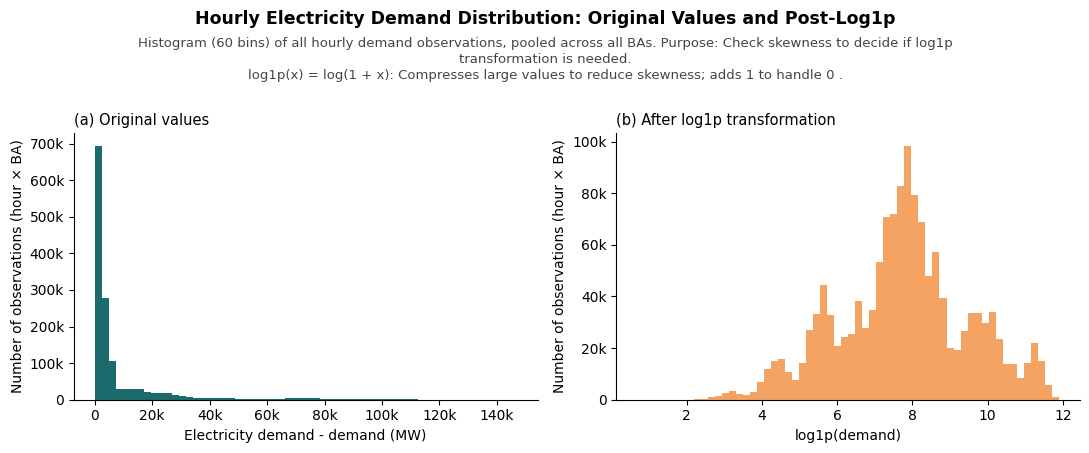

skewness: 3.42 -> consider log1p if skewness > 2


In [25]:
#Phân phối target: histogram gốc và log1p (EDA 2)
pos = df[TARGET_COL][df[TARGET_COL] > 0]
skew_raw, skew_log = df[TARGET_COL].skew(), np.log1p(pos).skew()
mean_v, med_v = df[TARGET_COL].mean(), df[TARGET_COL].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df[TARGET_COL], bins=60, color=TEAL)
axes[0].set_title("(a) Original values", fontsize=10.5, loc="left")
axes[0].set_xlabel("Electricity demand - " + TARGET_COL + " (MW)"); axes[0].set_ylabel("Number of observations (hour × BA)")
axes[0].xaxis.set_major_formatter(fmt_k); axes[0].yaxis.set_major_formatter(fmt_k)

axes[1].hist(np.log1p(pos), bins=60, color=ACC)
axes[1].set_title("(b) After log1p transformation", fontsize=10.5, loc="left")
axes[1].set_xlabel("log1p(" + TARGET_COL + ")"); axes[1].set_ylabel("Number of observations (hour × BA)")
axes[1].yaxis.set_major_formatter(fmt_k)
for ax in axes: style(ax)

savefig_annotated(
    fig, "fig_eda_distribution",
    title="Hourly Electricity Demand Distribution: Original Values and Post-Log1p",
    subtitle=("Histogram (60 bins) of all hourly demand observations, pooled across all BAs. "
              "Purpose: Check skewness to decide if log1p transformation is needed.\n"
              "log1p(x) = log(1 + x): Compresses large values to reduce skewness; adds 1 to handle 0 ."),
)  
print("skewness:", round(df[TARGET_COL].skew(), 2), "-> consider log1p if skewness > 2")

#### EDA 3 — Chuỗi thời gian demand của 4 BA đầu tiên (2022 - 2024)

**Biểu đồ này cho thấy**: nhu cầu điện theo giờ của 4 BA, mùa hè (T6 - T8) được tô cam và mốc chia Train/Test được vẽ bằng đường nét đứt.

**Vì sao cần vẽ**: để nhìn trực tiếp mùa vụ theo năm, khác biệt quy mô giữa các BA, và xem tập kiểm thử rơi vào giai đoạn nào của chu kỳ.

**Cách đọc**: mỗi màu là một BA (tên nằm ở chú giải phía trên hình); đường nét đứt chia tập huấn luyện (bên trái) và kiểm thử (bên phải).

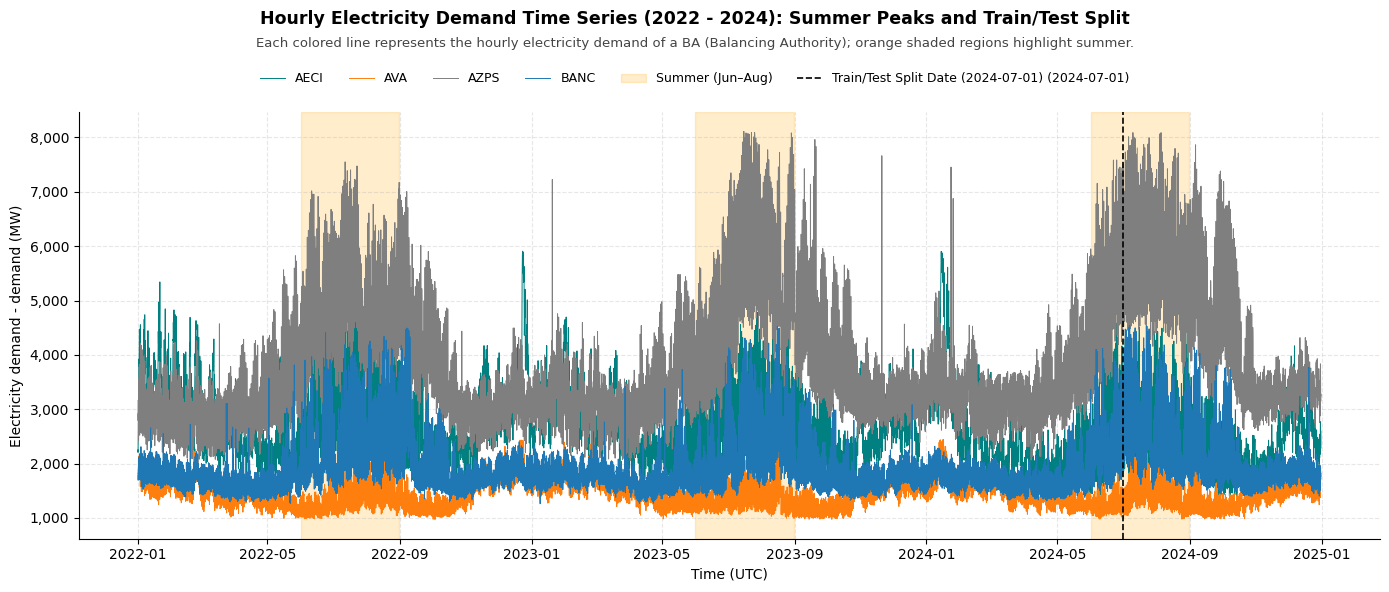

In [26]:
#Chuỗi thời gian của 4 BA đầu tiên (EDA 3)
import matplotlib.pyplot as plt
import pandas as pd

# 1. Đảm bảo cột thời gian đúng định dạng datetime
df[TIME_COL] = pd.to_datetime(df[TIME_COL])

# 2. Lọc lấy dữ liệu từ 2022 đến 2024 cho 4 BA đầu tiên
df_period = df[
    (df[TIME_COL] >= "2022-01-01") & (df[TIME_COL] <= "2024-12-31")
].copy()
units = df_period[UNIT_COL].unique()[:4]

fig, ax = plt.subplots(figsize=(14, 5))

# 3. Vẽ đường chuỗi thời gian cho 4 BA
colors = ["#008080", "#FF7F0E", "#7F7F7F", "#1F77B4"]
unit_means = {}
for u, col in zip(units, colors):
    g = df_period[df_period[UNIT_COL] == u]
    unit_means[u] = g[TARGET_COL].mean()
    ax.plot(g[TIME_COL], g[TARGET_COL], lw=0.7, color=col, label=str(u))

# 4. Highlight (Tô màu cam) các khoảng Mùa Hè (T6 - T8) cho cả 3 năm 2022, 2023, 2024
summer_periods = [
    ("2022-06-01", "2022-08-31"),
    ("2023-06-01", "2023-08-31"),
    ("2024-06-01", "2024-08-31"),
]
for i, (start, end) in enumerate(summer_periods):
    label = "Summer (Jun–Aug)" if i == 0 else ""
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="orange", alpha=0.2, label=label)

# 5. Thanh nét đứt màu đen chia tập Train/Test (Mốc TEST_START)
ax.axvline(pd.Timestamp(TEST_START), color="k", ls="--", lw=1.2, label=f"Train/Test Split Date (2024-07-01) ({TEST_START})")

# 6. Trục và lưới (tiêu đề, legend, nhận xét do annotate_fig đặt NGOÀI vùng vẽ)
ax.set_xlabel("Time (UTC)", fontsize=10)
ax.set_ylabel("Electricity demand - " + TARGET_COL + " (MW)", fontsize=10)
ax.yaxis.set_major_formatter(fmt_int)
ax.grid(True, linestyle="--", alpha=0.3)
style(ax)

BA_NAMES = {"AECI": "Associated Electric Cooperative", "AVA": "Avista", "AZPS": "Arizona Public Service",
            "BANC": "Balancing Authority of Northern California"}
ba_txt = "; ".join(f"{u} = {BA_NAMES[u]}" for u in units if u in BA_NAMES)
hi_u, lo_u = max(unit_means, key=unit_means.get), min(unit_means, key=unit_means.get)
split_note = ("Test set begins in the middle of summer 2024 peak, making it a challenging test for models."
              if pd.Timestamp(TEST_START).month in (6, 7, 8) else "")

savefig_annotated(
    fig, "fig_eda_timeseries_summer_split",
    title=f"Hourly Electricity Demand Time Series (2022 - 2024): Summer Peaks and Train/Test Split",
    subtitle="Each colored line represents the hourly electricity demand of a BA (Balancing Authority); orange shaded regions highlight summer.",
    
    legend_from=ax, legend_ncol=7, dpi=200,
)

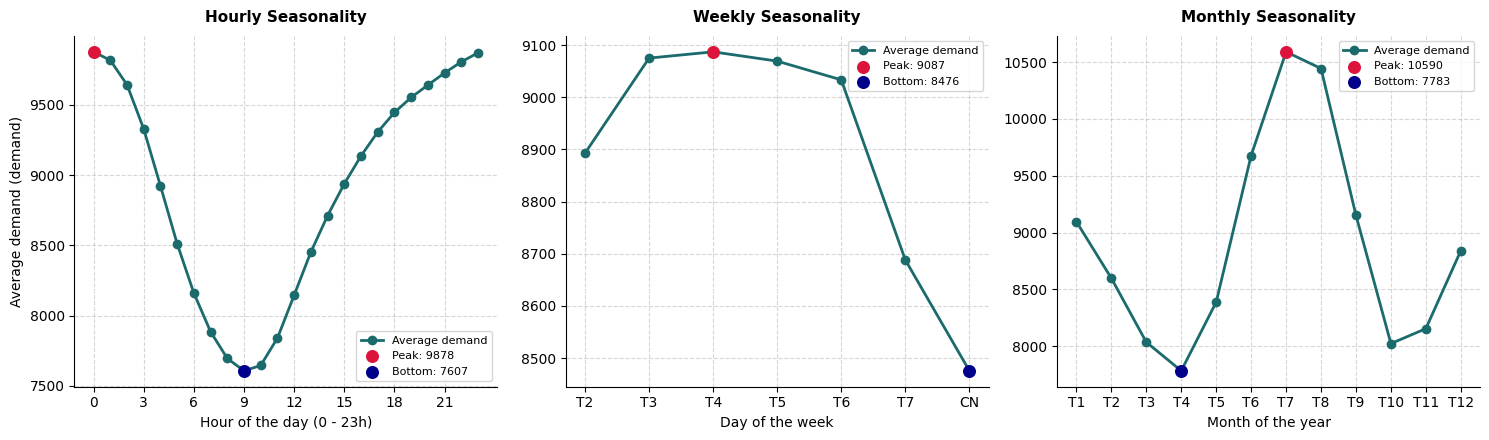

Seasonality strength (group mean std / overall std): {'hour': np.float64(0.045), 'dow': np.float64(0.013), 'month': np.float64(0.052)}


In [27]:
#Mùa vụ theo giờ/thứ/tháng (EDA 4)
import matplotlib.pyplot as plt
import pandas as pd

# 1. Trích xuất thông tin thời gian và tạo DataFrame phân tích
t = pd.to_datetime(df[TIME_COL])
cal = pd.DataFrame({
    "hour": t.dt.hour,
    "dow": t.dt.dayofweek,
    "month": t.dt.month,
    TARGET_COL: df[TARGET_COL],
})

# 2. Khởi tạo Figure với kích thước chuẩn đẹp
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Đặt tên nhãn hiển thị trực quan cho từng subplot
configs = [
    {
        "col": "hour",
        "title": "Hourly Seasonality",
        "xlabel": "Hour of the day (0 - 23h)",
        "xticks": range(0, 24, 3),
        "xticklabels": None,
    },
    {
        "col": "dow",
        "title": "Weekly Seasonality",
        "xlabel": "Day of the week",
        "xticks": range(0, 7),
        "xticklabels": ["T2", "T3", "T4", "T5", "T6", "T7", "CN"],
    },
    {
        "col": "month",
        "title": "Monthly Seasonality",
        "xlabel": "Month of the year",
        "xticks": range(1, 13),
        "xticklabels": [
            "T1",
            "T2",
            "T3",
            "T4",
            "T5",
            "T6",
            "T7",
            "T8",
            "T9",
            "T10",
            "T11",
            "T12",
        ],
    },
]

# 3. Vẽ từng biểu đồ
for ax, cfg in zip(axes, configs):
    k = cfg["col"]
    s = cal.groupby(k)[TARGET_COL].mean()

    # Vẽ đường xu hướng với điểm marker rõ ràng
    ax.plot(
        s.index,
        s.values,
        marker="o",
        linewidth=2,
        markersize=6,
        color=TEAL,
        label="Average demand",
    )

    # Highlight giá trị Đỉnh (Max) và Đáy (Min)
    max_idx, max_val = s.idxmax(), s.max()
    min_idx, min_val = s.idxmin(), s.min()
    ax.scatter(
        [max_idx],
        [max_val],
        color="crimson",
        s=70,
        zorder=5,
        label=f"Peak: {max_val:.0f}",
    )
    ax.scatter(
        [min_idx],
        [min_val],
        color="darkblue",
        s=70,
        zorder=5,
        label=f"Bottom: {min_val:.0f}",
    )

    # Tinh chỉnh Trục X
    ax.set_xticks(cfg["xticks"])
    if cfg["xticklabels"]:
        ax.set_xticklabels(cfg["xticklabels"])

    # Định dạng nhãn và tiêu đề
    ax.set_title(cfg["title"], fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel(cfg["xlabel"], fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(frameon=True, fontsize=8, loc="best")

    # Áp dụng hàm style riêng của bạn (nếu có)
    style(ax)

# Đặt nhãn Trục Y chung cho cả hình
axes[0].set_ylabel(f"Average demand ({TARGET_COL})", fontsize=10)

plt.tight_layout()
savefig(fig, "fig_eda_seasonality")
plt.show()

# 4. Tính toán và in độ mạnh mùa vụ (Seasonality Strength)
season_strength = {
    k: round(cal.groupby(k)[TARGET_COL].mean().std() / cal[TARGET_COL].std(), 3)
    for k in ["hour", "dow", "month"]
}
print(
    "Seasonality strength (group mean std / overall std):",
    season_strength,
)

**Luu y doc ket qua `season_strength` o tren**: cac gia tri nay tinh tren `df` gop chung ca 53 BA, trong khi ty le mean giua BA lon nhat/nho nhat la ~2052 lan (xem EDA 5 ben duoi) - vai BA rat lon (PJM, MISO...) ap dao std tong, lam loang tin hieu mua vu that cua tung don vi rieng le. Do khong phai loi tinh toan, ma la gioi han cua cach gop du lieu; khi viet RQ1 can ghi ro gioi han nay, hoac tinh lai season_strength sau khi chuan hoa (z-score/log) theo tung BA neu muon con so phan anh dung mua vu noi tai hon.

Largest BA: PJM (91,645.6) | Smallest BA: SPA (44.7)
Ratio of max / min mean across BAs: 2051.95 lần


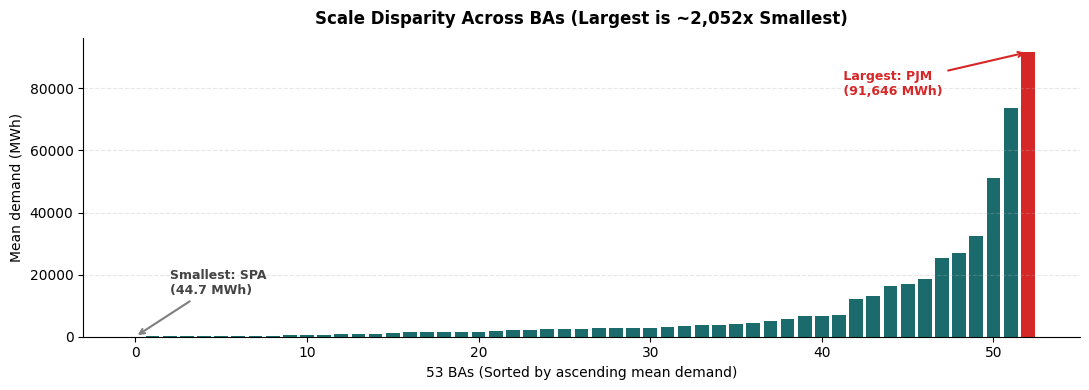

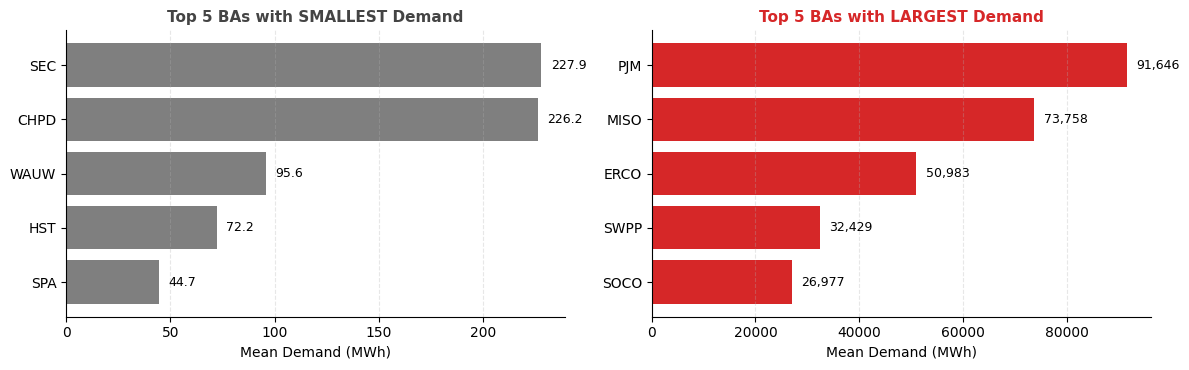

In [28]:
#Khác biệt giữa các BA (EDA 5)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Gom nhóm và tính toán thống kê theo từng BA
per_unit = (
    df.groupby(UNIT_COL)[TARGET_COL]
    .agg(["mean", "std", "min", "max", "count"])
    .sort_values("mean")
)
per_unit.to_csv("report/table_per_unit.csv")

# In tỷ lệ chênh lệch
max_ba_name = per_unit["mean"].idxmax()
min_ba_name = per_unit["mean"].idxmin()
max_val = per_unit["mean"].max()
min_val = per_unit["mean"].min()
ratio = round(max_val / max(min_val, 1e-9), 2)

print(
    f"Largest BA: {max_ba_name} ({max_val:,.1f}) | Smallest BA: {min_ba_name} ({min_val:,.1f})"
)
print(f"Ratio of max / min mean across BAs: {ratio} lần")

# =========================================================
# BIỂU ĐỒ 1: Biểu đồ tổng quan 53 BA có Annotate Đỉnh/Đáy
# =========================================================
fig, ax = plt.subplots(figsize=(11, 4))

# Tô màu riêng cho BA nhỏ nhất (màu xám) và BA lớn nhất (màu đỏ)
colors = [TEAL] * len(per_unit)
colors[-1] = "#D62728"  # Đỏ cho BA lớn nhất
colors[0] = "#7F7F7F"  # Xám cho BA nhỏ nhất

bars = ax.bar(range(len(per_unit)), per_unit["mean"], color=colors, width=0.8)

# Thêm ghi chú (Annotation) cho BA lớn nhất
ax.annotate(
    f" Largest: {max_ba_name}\n ({max_val:,.0f} MWh)",
    xy=(len(per_unit) - 1, max_val),
    xytext=(len(per_unit) - 12, max_val * 0.85),
    arrowprops=dict(
        facecolor="#D62728", edgecolor="#D62728", arrowstyle="->", lw=1.5
    ),
    fontsize=9,
    fontweight="bold",
    color="#D62728",
)

# Thêm ghi chú (Annotation) cho BA nhỏ nhất
ax.annotate(
    f"Smallest: {min_ba_name}\n({min_val:,.1f} MWh)",
    xy=(0, min_val),
    xytext=(2, max_val * 0.15),
    arrowprops=dict(
        facecolor="#7F7F7F", edgecolor="#7F7F7F", arrowstyle="->", lw=1.5
    ),
    fontsize=9,
    fontweight="bold",
    color="#444444",
)

ax.set_xlabel("53 BAs (Sorted by ascending mean demand)", fontsize=10)
ax.set_ylabel(f"Mean {TARGET_COL} (MWh)", fontsize=10)
ax.set_title(
    f"Scale Disparity Across BAs (Largest is ~{ratio:,.0f}x Smallest)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax.grid(True, axis="y", linestyle="--", alpha=0.3)
style(ax)

plt.tight_layout()
savefig(fig, "fig_eda_units")
plt.show()

# =========================================================
# BIỂU ĐỒ 2: So sánh trực tiếp Top 5 BA Lớn nhất vs Top 5 BA Nhỏ nhất
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

top5_min = per_unit.head(5)
top5_max = per_unit.tail(5)

# Biểu đồ Top 5 nhỏ nhất
axes[0].barh(top5_min.index, top5_min["mean"], color="#7F7F7F")
axes[0].set_title(
    "Top 5 BAs with SMALLEST Demand", fontsize=11, fontweight="bold", color="#444444"
)
axes[0].set_xlabel("Mean Demand (MWh)")
for i, v in enumerate(top5_min["mean"]):
    axes[0].text(v + (top5_min["mean"].max() * 0.02), i, f"{v:,.1f}", va="center", fontsize=9)

# Biểu đồ Top 5 lớn nhất
axes[1].barh(top5_max.index, top5_max["mean"], color="#D62728")
axes[1].set_title(
    "Top 5 BAs with LARGEST Demand", fontsize=11, fontweight="bold", color="#D62728"
)
axes[1].set_xlabel("Mean Demand (MWh)")
for i, v in enumerate(top5_max["mean"]):
    axes[1].text(v + (top5_max["mean"].max() * 0.02), i, f"{v:,.0f}", va="center", fontsize=9)

for ax in axes:
    ax.grid(True, axis="x", linestyle="--", alpha=0.3)
    style(ax)

plt.tight_layout()
savefig(fig, "fig_eda_top_bottom_units")
plt.show()

#### EDA 6 — Demand theo mức cường độ CO2 (hai biểu đồ, mỗi biểu đồ một biến CO2)

**Biểu đồ này cho thấy**: demand trung bình thay đổi thế nào khi cường độ CO2 tăng từ nhóm thấp nhất (decile 0) đến cao nhất (decile 9). Hai biểu đồ lần lượt là CO2 của điện **được phát** (`generated`) và **được tiêu thụ** (`consumed`).

**Vì sao cần vẽ**: kiểm tra xem biến phụ CO2 có liên hệ với demand hay không, và liên hệ đó đơn điệu hay có dạng cong. Bảng Spearman ở cuối ô bổ sung con số tương ứng.

**Lưu ý**: CO2 chỉ có ở một nhóm BA miền Tây, nên kết quả chỉ áp dụng cho nhóm này.

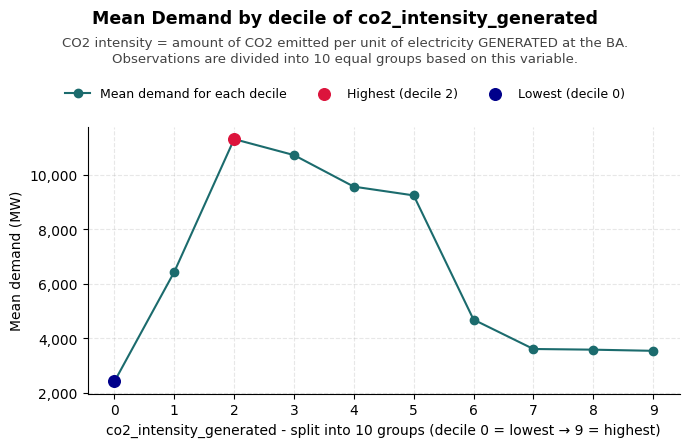

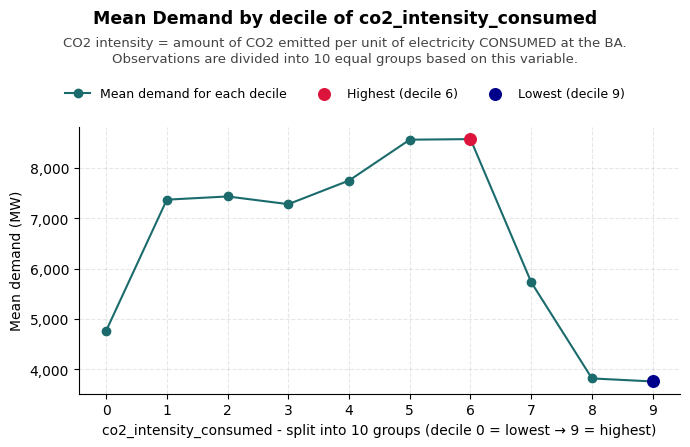

,covariate,spearman_rho,p_value,n
0,co2_intensity_generated,-0.108,0.000000e+00,210215
1,co2_intensity_consumed,-0.018,2.609095e-17,209301


In [29]:
#Tương quan với biến phụ CO2 (EDA 6)
from scipy.stats import spearmanr
COV_DESC = {"co2_intensity_generated": "electricity GENERATED at the BA", "co2_intensity_consumed": "electricity CONSUMED at the BA"}
rows = []
for c in [c for c in EXOG_COLS if c in df.columns]:
    ok = df[[c, TARGET_COL]].dropna()
    rho, p = spearmanr(ok[c], ok[TARGET_COL])
    rows.append([c, round(rho, 3), p, len(ok)])

    b = ok.groupby(pd.qcut(ok[c], 10, duplicates="drop"), observed=True)[TARGET_COL].mean()
    x, y = np.arange(len(b)), b.values
    k_max, k_min = int(np.argmax(y)), int(np.argmin(y))

    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.plot(x, y, marker="o", color=TEAL, label="Mean demand for each decile")
    ax.scatter([k_max], [y[k_max]], color="crimson", s=70, zorder=5, label=f"Highest (decile {k_max})")
    ax.scatter([k_min], [y[k_min]], color="darkblue", s=70, zorder=5, label=f"Lowest (decile {k_min})")
    ax.set_xticks(x)
    ax.set_xlabel(f"{c} - split into 10 groups (decile {x[0]} = lowest → {x[-1]} = highest)")
    ax.set_ylabel("Mean demand (MW)")
    ax.yaxis.set_major_formatter(fmt_int)
    ax.grid(True, linestyle="--", alpha=0.3); style(ax)

    non_mono = 0 < k_max < len(y) - 1
    shape = f"non-monotonic: increases up to decile {k_max} then decreases" if non_mono else ("increases with CO2 level" if k_max == len(y) - 1 else "decreases with CO2 level")
    mono_note = "Because the curve is non-monotonic, a single ρ value (which only measures monotonic trends) does not fully capture the relationship." if non_mono else ""

    savefig_annotated(
        fig, "fig_eda_covariate_" + c,
        title=f"Mean Demand by decile of {c}",
        subtitle=f"CO2 intensity = amount of CO2 emitted per unit of {COV_DESC.get(c, c)}. Observations are divided into 10 equal groups based on this variable.",
        
        legend_from=ax, legend_ncol=3,
    )

corr_tbl = pd.DataFrame(rows, columns=["covariate", "spearman_rho", "p_value", "n"])
corr_tbl.to_csv("report/table_covariate_corr.csv", index=False)
display(corr_tbl)

#### EDA 7 — Tương quan chéo giữa CO2 và demand theo độ trễ

**Biểu đồ này cho thấy**: nếu lấy CO2 của k giờ trước thì nó tương quan với demand hiện tại đến mức nào, với k từ 0 đến 96 giờ.

**Vì sao cần vẽ**: để xem CO2 có mang thông tin dẫn trước demand hay không, từ đó quyết định có tạo đặc trưng trễ của CO2 hay không.

**Cách đọc**: trục ngang là độ trễ (giờ), trục dọc là hệ số tương quan; các vạch chấm mờ đánh dấu các mốc bội của 24 giờ (1 ngày).

co2_intensity_generated best lag: 18 corr: 0.267
co2_intensity_consumed best lag: 18 corr: 0.275


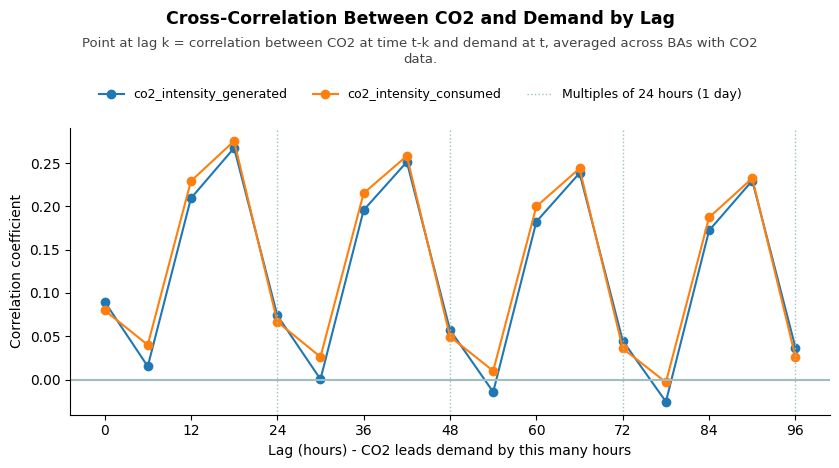

In [30]:
#Độ trễ (lag) giữa CO2 và demand (EDA 7)
def cross_corr(g, x, y, lags):
    return [g[y].corr(g[x].shift(k)) for k in lags]

lags = list(range(0, 4 * SEASON + 1, max(1, SEASON // 4)))
fig, ax = plt.subplots(figsize=(8.5, 3.6))
best, curves, n_ba = {}, {}, 0
for c in [c for c in EXOG_COLS if c in df.columns][:3]:
    arrs = np.array([cross_corr(g, c, TARGET_COL, lags) for _, g in df.groupby(UNIT_COL) if len(g) > 5 * SEASON], dtype=float)
    arrs = arrs[~np.all(np.isnan(arrs), axis=1)]          # chỉ giữ BA thật sự có dữ liệu CO2
    n_ba = max(n_ba, len(arrs))
    cc = np.nanmean(arrs, axis=0)
    curves[c] = cc
    best[c] = (lags[int(np.nanargmax(np.abs(cc)))], float(np.nanmax(np.abs(cc))))
    ax.plot(lags, cc, marker="o", label=c)
    print(c, "best lag:", best[c][0], "corr:", round(best[c][1], 3))

# vạch mờ tại các mốc bội của SEASON (1 ngày, 2 ngày, ...) để thấy chu kỳ ngày
for i, k in enumerate(range(SEASON, lags[-1] + 1, SEASON)):
    ax.axvline(k, color=GREY, ls=":", lw=1, label=f"Multiples of {SEASON} hours (1 day)" if i == 0 else None)
ax.axhline(0, color=GREY)
ax.set_xlabel("Lag (hours) - CO2 leads demand by this many hours"); ax.set_ylabel("Correlation coefficient"); style(ax)
ax.set_xticks(range(0, lags[-1] + 1, SEASON // 2))

top_c = max(best, key=lambda k: best[k][1]); top_lag, top_r = best[top_c]
pk = [lags[i] for i in range(1, len(lags) - 1) if curves[top_c][i] > curves[top_c][i - 1] and curves[top_c][i] > curves[top_c][i + 1]]
strength = "" if top_r < 0.3 else ("trung bình" if top_r < 0.6 else "mạnh")
strength = "weak" if top_r < 0.3 else ("moderate" if top_r < 0.6 else "strong")
periodic = len(pk) >= 2 and all(np.diff(pk) == SEASON)
period_txt = (f"The curve repeats regularly with a cycle of {SEASON} hours (peaks at lags {', '.join(map(str, pk))}) because both CO2 and demand follow day-night patterns, "
              f"so this should not be interpreted as CO2 'leading' demand." if periodic else "")

savefig_annotated(
    fig, "fig_eda_crosscorr",
    title="Cross-Correlation Between CO2 and Demand by Lag",
    subtitle="Point at lag k = correlation between CO2 at time t-k and demand at t, averaged across BAs with CO2 data.",
    
    legend_from=ax, legend_ncol=3,
)

**Luu y doc ket qua "best lag" o tren**: cac gia tri co the cao hon tuong quan Spearman dong thoi o EDA 6 vi ham nay chon |corr| lon nhat trong ~24 do tre ung vien (de bi "chon so dep nhat trong nhieu lan thu" - multiple comparison), va chi trung binh tren nhung BA co it nhat 5*SEASON dong VA co du lieu CO2 (chi 8/53 BA). Khi viet RQ1, nen uu tien nêu con so Spearman dong thoi (dang tin hon) va ghi ro: cac phat hien ve CO2 chi ap dung cho 8 BA co trong nguon phu (AZPS, BPAT, CISO, LDWP, NEVP, PACW, PGE, SRP - deu thuoc mien Tay), khong dai dien cho 53 BA con lai, vi CO2 chi phu ~15% so dong.

#### EDA 8 — Tự tương quan (ACF) của demand

**Biểu đồ này cho thấy**: demand của một giờ giống demand của k giờ trước đó đến mức nào, với k từ 0 đến 49 giờ.

**Vì sao cần vẽ**: ACF cho biết nên dùng những độ trễ nào làm đặc trưng và baseline "lặp lại giá trị cùng giờ hôm qua" (seasonal-naive) có đủ mạnh hay không.

**Cách đọc**: mỗi cột là ACF tại một độ trễ; các vạch cam đứt nét là lag 24 và 48 (đúng 1 và 2 ngày trước).

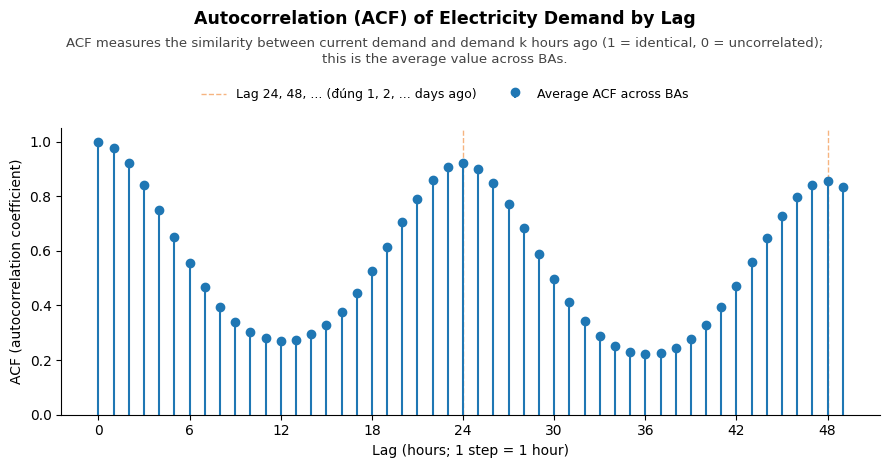

ACF at lag 1: 0.976 | at SEASON: 0.922 -> seasonal-naive is strong if ACF at SEASON > 0.7


In [31]:
#Tự tương quan (ACF) để chọn lag làm feature (EDA 8)
from statsmodels.tsa.stattools import acf
nl = 2 * SEASON + 1
acfs = [acf(g[TARGET_COL].values, nlags=nl, fft=True) for _, g in df.groupby(UNIT_COL) if len(g) > 4 * SEASON]
acf_mean = np.mean(acfs, axis=0)

fig, ax = plt.subplots(figsize=(9, 3.6))
for i, k in enumerate(range(SEASON, nl + 1, SEASON)):
    ax.axvline(k, color=ACC, ls="--", lw=1, alpha=0.8, zorder=0,
               label=f"Lag {SEASON}, {2 * SEASON}, ... (đúng 1, 2, ... days ago)" if i == 0 else None)
ax.stem(range(nl + 1), acf_mean, basefmt=" ", label="Average ACF across BAs")
ax.set_ylim(0, 1.05)
ax.set_xticks(range(0, nl + 1, SEASON // 4))
ax.set_xlabel("Lag (hours; 1 step = 1 hour)"); ax.set_ylabel("ACF (autocorrelation coefficient)"); style(ax)

a1, aS, a2S = acf_mean[1], acf_mean[SEASON], acf_mean[2 * SEASON]
trough = int(np.argmin(acf_mean[:SEASON + 1]))
strong = aS > 0.7
savefig_annotated(
    fig, "fig_eda_acf",
    title="Autocorrelation (ACF) of Electricity Demand by Lag",
    subtitle="ACF measures the similarity between current demand and demand k hours ago (1 = identical, 0 = uncorrelated); this is the average value across BAs.",
    
    legend_from=ax, legend_ncol=2,
)
print("ACF at lag 1:", round(acf_mean[1], 3), "| at SEASON:", round(acf_mean[SEASON], 3), "-> seasonal-naive is strong if ACF at SEASON > 0.7")

#### EDA 9 — Thiếu dữ liệu và kiểm tra thay đổi chế độ (regime shift)

**Hai biểu đồ trong ô này**:
1. **Heatmap thiếu dữ liệu**: tỷ lệ giờ bị thiếu theo từng BA và từng tháng sau khi làm sạch.
2. **Demand trung bình theo tháng**: kiểm tra xem mức demand có chuyển sang một mức nền khác sau mốc Train/Test hay không.

**Vì sao cần vẽ**: chuỗi thiếu nhiều làm các đặc trưng trễ và cửa sổ trượt kém tin cậy; nếu có regime shift thì kết quả kiểm thử không còn phản ánh giai đoạn huấn luyện.

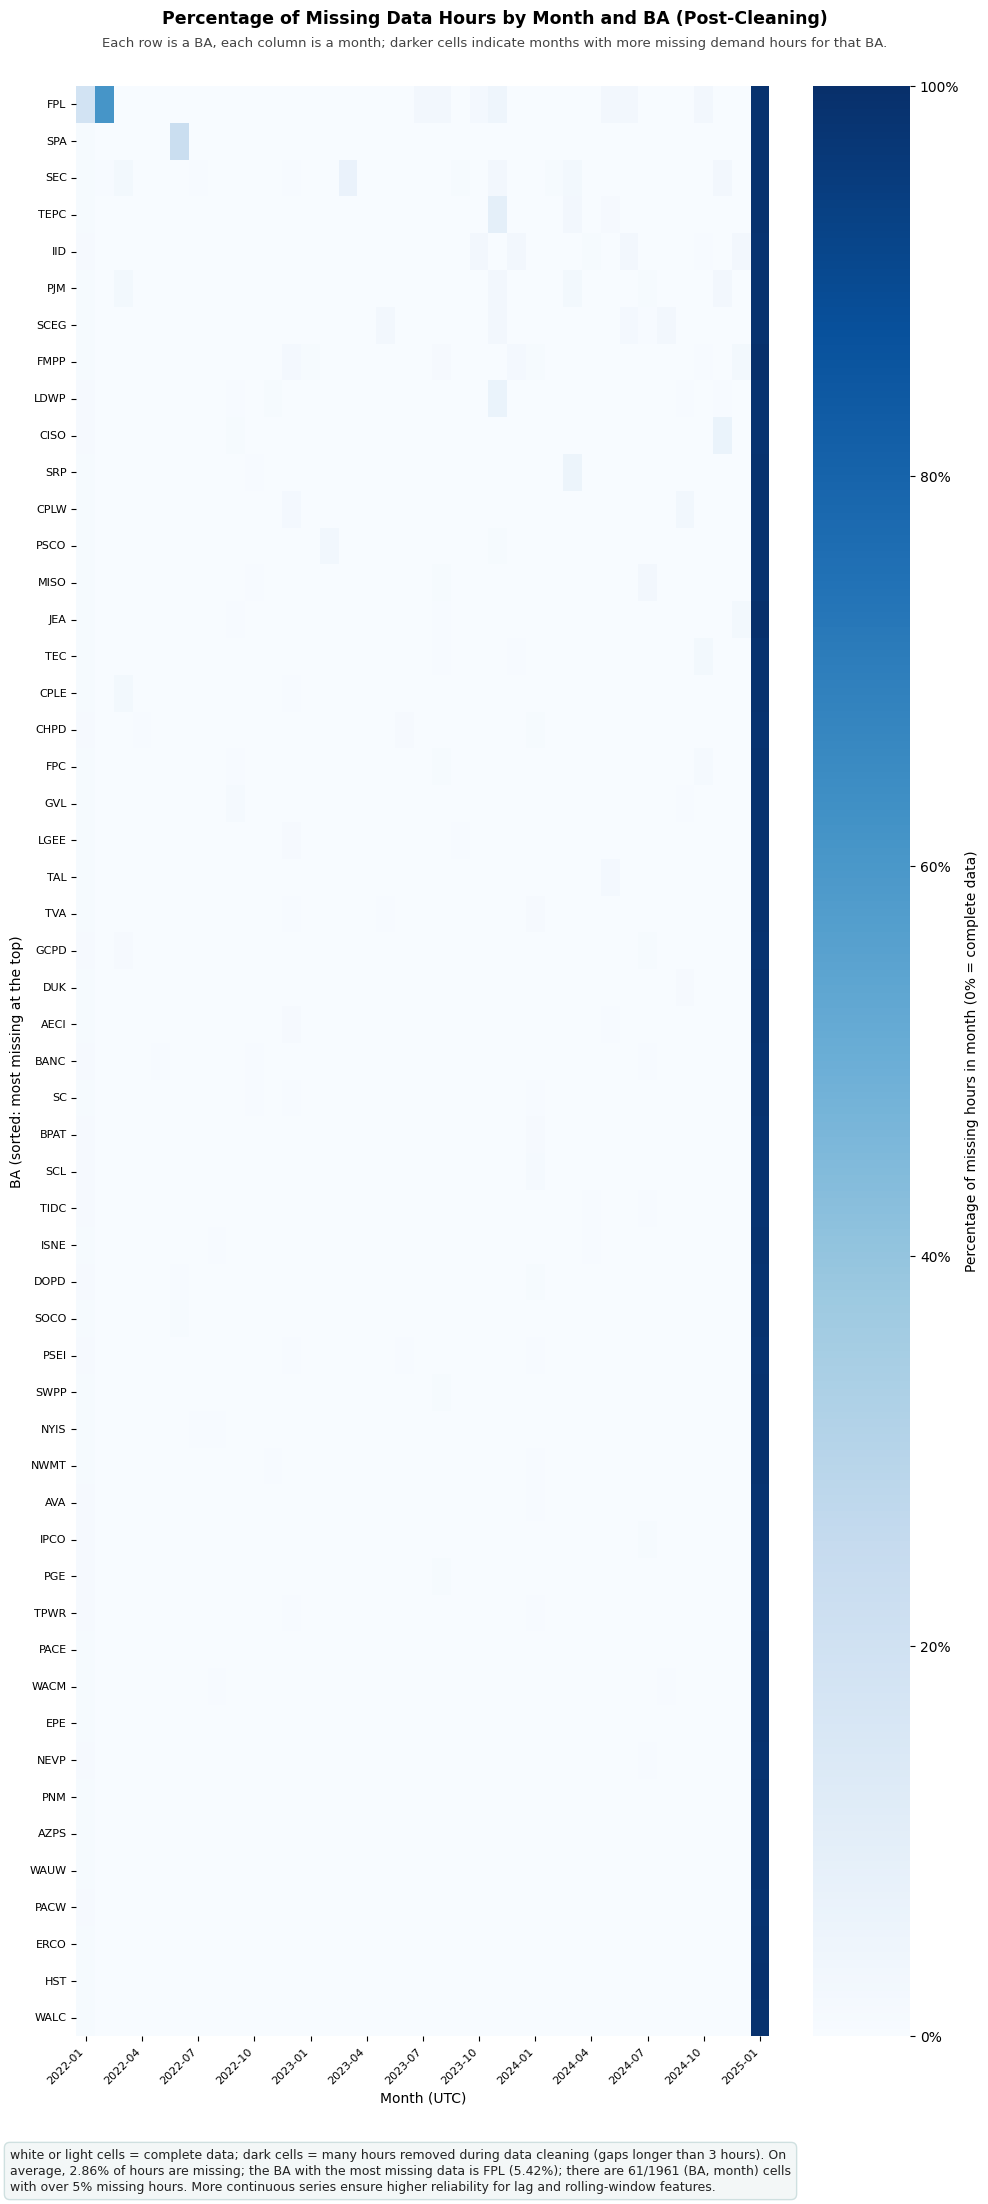

average missing share post-cleaning: 0.0286
BA with highest missing share: FPL = 0.05416


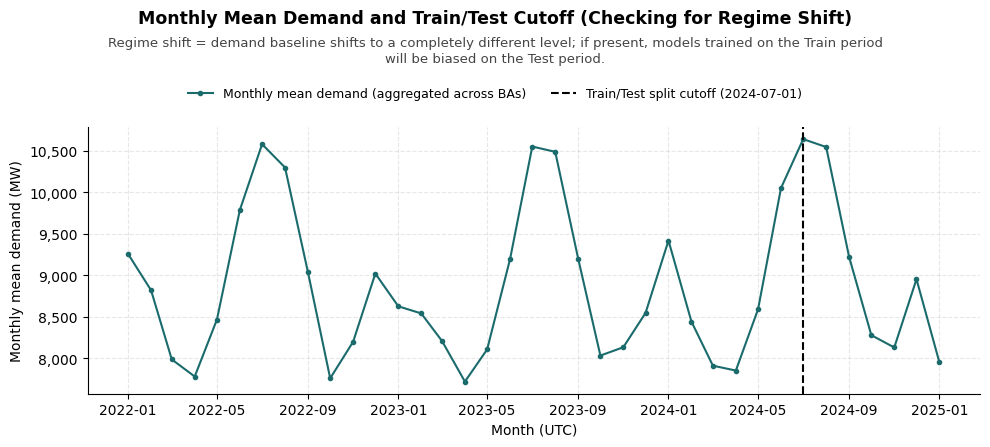

largest monthly fluctuation (ratio relative to mean): 0.165 -> above 0.5 indicates a regime shift; if present, state clearly in RQ3


In [32]:
#Kiểm tra thiếu dữ liệu theo thời gian + regime shift (EDA 9)
import seaborn as sns

# --- Hình 1: tỷ lệ giờ thiếu theo (BA, tháng) ---
# Sau bước làm sạch, các giờ thiếu dài đã bị loại khỏi bảng, nên "thiếu" = số giờ kỳ vọng trong tháng mà BA không còn dòng dữ liệu.
tmp = df[[UNIT_COL, TIME_COL]].copy()
tmp["month"] = pd.to_datetime(tmp[TIME_COL]).dt.to_period("M").dt.to_timestamp()
have = tmp.groupby([UNIT_COL, "month"]).size().unstack(0)
months = pd.date_range(have.index.min(), have.index.max(), freq="MS")
have = have.reindex(months).fillna(0)
miss = (1 - have.div((months.days_in_month * 24).to_numpy(), axis=0)).clip(lower=0).astype(float)
miss = miss[miss.mean().sort_values(ascending=False).index]      # BA thiếu nhiều nhất nằm trên cùng

fig, ax = plt.subplots(figsize=(10, 0.35 * miss.shape[1] + 2))  # cao theo so BA, tranh chong chu
sns.heatmap(miss.T, cmap="Blues", vmin=0, vmax=max(float(miss.values.max()), 0.01), ax=ax,
            cbar_kws={"label": "Percentage of missing hours in month (0% = complete data)", "format": fmt_pct},
            yticklabels=True, xticklabels=3)
ax.set_xticklabels([miss.index[i].strftime("%Y-%m") for i in range(0, len(miss.index), 3)], rotation=45, ha="right", fontsize=8)
ax.set_xlabel("Month (UTC)"); ax.set_ylabel("BA (sorted: most missing at the top)")
ax.tick_params(axis="y", labelsize=8, rotation=0)

worst_ba, worst_share = miss.mean(axis=0).idxmax(), miss.mean(axis=0).max()
n_bad = int((miss > 0.05).values.sum())
savefig_annotated(
    fig, "fig_eda_missing",
    title="Percentage of Missing Data Hours by Month and BA (Post-Cleaning)",
    subtitle="Each row is a BA, each column is a month; darker cells indicate months with more missing demand hours for that BA.",
    caption=(f"white or light cells = complete data; dark cells = many hours removed during data cleaning (gaps longer than 3 hours). "
             f"On average, {miss.values.mean():.2%} of hours are missing; the BA with the most missing data is {worst_ba} ({worst_share:.2%}); "
             f"there are {n_bad}/{miss.size} (BA, month) cells with over 5% missing hours. More continuous series ensure higher reliability for lag and rolling-window features."),
)
print("average missing share post-cleaning:", round(miss.values.mean(), 5))
print("BA with highest missing share:", worst_ba, "=", round(worst_share, 5))

# --- Hình 2: demand trung bình theo tháng + mốc chia Train/Test (kiểm tra regime shift) ---
roll = df.set_index(TIME_COL)[TARGET_COL].resample("MS").mean()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(roll.index, roll.values, color=TEAL, marker="o", ms=3, label="Monthly mean demand (aggregated across BAs)")
ax.axvline(pd.Timestamp(TEST_START), color="k", ls="--", label=f"Train/Test split cutoff ({TEST_START})")
ax.set_xlabel("Month (UTC)"); ax.set_ylabel("Monthly mean demand (MW)")
ax.yaxis.set_major_formatter(fmt_int)
ax.grid(True, linestyle="--", alpha=0.3); style(ax)

jump = roll.diff().abs().max() / roll.mean()
pk_txt = ", ".join(t.strftime("%Y-%m") for t in roll.groupby(roll.index.year).idxmax())
verdict = ("no signs of regime shift yet, fluctuations are mainly seasonal" if jump <= 0.5
           else "signs of regime shift detected, should be clearly stated in RQ3")
savefig_annotated(
    fig, "fig_eda_regime",
    title="Monthly Mean Demand and Train/Test Cutoff (Checking for Regime Shift)",
    subtitle="Regime shift = demand baseline shifts to a completely different level; if present, models trained on the Train period will be biased on the Test period.",
    
    legend_from=ax, legend_ncol=2,
)
print("largest monthly fluctuation (ratio relative to mean):", round(jump, 3), "-> above 0.5 indicates a regime shift; if present, state clearly in RQ3")

## Bước 3: SQL với DuckDB, trả lời RQ1 và tạo bảng đặc trưng

**Vì sao SQL**: người đọc bài kiểm tra được từng con số bằng một truy vấn; đặc trưng trễ và cửa sổ trượt bằng `WINDOW` không rò rỉ tương lai nếu chỉ dùng `LAG` và `PRECEDING`.

**Quy tắc chống rò rỉ**: đặc trưng chỉ dùng thông tin **tại hoặc trước** thời điểm t; mục tiêu là `LEAD(target, h)`; không dùng thống kê tính trên toàn chuỗi (kể cả trung bình đơn vị) trừ khi tính chỉ trên phần huấn luyện.

In [33]:
official_fc = con.execute("""
    SELECT
        "Balancing Authority" AS ba,
        CAST("UTC Time at End of Hour" AS TIMESTAMP) AS ts_utc,
        "Demand Forecast (MW)" AS eia_fc
    FROM read_csv_auto('data/raw/EIA930_BALANCE_2022_2024.csv', SAMPLE_SIZE=-1)
""").df()

n_before = len(df)
df = df.merge(official_fc, on=["ba", "ts_utc"], how="left")
n_after = len(df)
print(f"ghep du bao chinh thuc EIA (eia_fc): {n_before:,} -> {n_after:,}")
print(f"So dong co eia_fc: {df['eia_fc'].notna().sum():,} / {n_after:,} ({df['eia_fc'].notna().mean()*100:.1f}%)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ghep du bao chinh thuc EIA (eia_fc): 1,391,895 -> 1,391,895
So dong co eia_fc: 1,386,234 / 1,391,895 (99.6%)


In [34]:
#Cell 3a — Đăng ký bảng sạch vào DuckDB + viết 4 truy vấn RQ1
con.register("clean", df)

EXOG_SQL = ", ".join([c for c in EXOG_COLS if c in df.columns]) or "NULL AS no_exog"

SQL_RQ1 = f"""
-- Q1: mean va do lech cua target theo tung don vi va theo thang
SELECT {UNIT_COL}, month({TIME_COL}) AS mon, AVG({TARGET_COL}) AS mean_target, STDDEV({TARGET_COL}) AS sd_target, COUNT(*) AS n
FROM clean GROUP BY 1, 2 ORDER BY 1, 2;
-- Q2: ty le buoc "su kien" (target vuot phan vi {EVENT_QUANTILE:.0%}) theo tung BA
WITH thr AS (SELECT quantile_cont({TARGET_COL}, {EVENT_QUANTILE}) AS q FROM clean)
SELECT {UNIT_COL}, AVG(({TARGET_COL} > q)::INT) AS event_share FROM clean, thr GROUP BY 1 ORDER BY 2 DESC;
-- Q3: target theo decile cua bien phu (quan he voi CO2)
SELECT decile, AVG({TARGET_COL}) AS mean_target, COUNT(*) AS n
FROM (SELECT NTILE(10) OVER (ORDER BY {EXOG_COLS[0]}) AS decile, {TARGET_COL} FROM clean WHERE {EXOG_COLS[0]} IS NOT NULL)
GROUP BY 1 ORDER BY 1;
-- Q4: tuong quan giua target va gia tri cach SEASON buoc truoc (kiem tra seasonal-naive)
SELECT corr({TARGET_COL}, lagged) AS r_season
FROM (SELECT {TARGET_COL}, LAG({TARGET_COL}, {SEASON}) OVER (PARTITION BY {UNIT_COL} ORDER BY {TIME_COL}) AS lagged FROM clean);
"""
open("sql/queries.sql", "w").write(SQL_RQ1)
print(SQL_RQ1)


-- Q1: mean va do lech cua target theo tung don vi va theo thang
SELECT ba, month(ts_utc) AS mon, AVG(demand) AS mean_target, STDDEV(demand) AS sd_target, COUNT(*) AS n
FROM clean GROUP BY 1, 2 ORDER BY 1, 2;
-- Q2: ty le buoc "su kien" (target vuot phan vi 90%) theo tung BA
WITH thr AS (SELECT quantile_cont(demand, 0.9) AS q FROM clean)
SELECT ba, AVG((demand > q)::INT) AS event_share FROM clean, thr GROUP BY 1 ORDER BY 2 DESC;
-- Q3: target theo decile cua bien phu (quan he voi CO2)
SELECT decile, AVG(demand) AS mean_target, COUNT(*) AS n
FROM (SELECT NTILE(10) OVER (ORDER BY co2_intensity_generated) AS decile, demand FROM clean WHERE co2_intensity_generated IS NOT NULL)
GROUP BY 1 ORDER BY 1;
-- Q4: tuong quan giua target va gia tri cach SEASON buoc truoc (kiem tra seasonal-naive)
SELECT corr(demand, lagged) AS r_season
FROM (SELECT demand, LAG(demand, 24) OVER (PARTITION BY ba ORDER BY ts_utc) AS lagged FROM clean);



In [35]:
#Cell 3b — Chạy toàn bộ file SQL, lưu kết quả từng câu
def run_sql_file(path):
    txt = open(path).read()
    body = "\n".join(l for l in txt.splitlines() if not l.strip().startswith("--"))
    k = 0
    for stmt in body.split(";"):
        stmt = stmt.strip()
        if not stmt:
            continue
        k += 1
        out = con.execute(stmt).df()
        out.to_csv(f"report/table_q{k}.csv", index=False)
        print(f"Q{k}: {out.shape}")
        display(out.head(8))

run_sql_file("sql/queries.sql")

Q1: (636, 5)


,ba,mon,mean_target,sd_target,n
0,AECI,1,3474.090054,727.925022,2232
1,AECI,2,2940.161275,676.947972,2040
2,AECI,3,2515.673835,497.695417,2232
3,AECI,4,2175.444213,326.123490,2160
4,AECI,5,2258.369044,480.454861,2229
5,AECI,6,2816.817130,741.272079,2160
6,AECI,7,3085.606631,785.558296,2232
7,AECI,8,2955.281362,751.035286,2232


Q2: (53, 2)


,ba,event_share
0,PJM,1.000000
1,MISO,1.000000
2,ERCO,1.000000
3,SWPP,0.979196
4,SOCO,0.630928
5,CISO,0.508972
6,TVA,0.097269
7,FPL,0.051869


Q3: (10, 3)


,decile,mean_target,n
0,1,2400.223986,21022
1,2,6326.464669,21022
2,3,11303.316778,21022
3,4,10716.252038,21022
4,5,9558.609198,21022
5,6,9237.195328,21021
6,7,4677.855498,21021
7,8,3598.744276,21021


Q4: (1, 1)


,r_season
0,0.997109


In [36]:
#Cell 3d — Tạo bảng đặc trưng feat bằng SQL WINDOW (lag, rolling, calendar, target theo horizon — không rò rỉ tương lai)
lag_list = sorted(set([1, 2, 3, SEASON, 2 * SEASON, 7 * SEASON]))
lag_sql = ", ".join([f"LAG({TARGET_COL}, {k}) OVER w AS y_lag{k}" for k in lag_list])
roll_sql = (
    f"AVG({TARGET_COL}) OVER (w ROWS BETWEEN {SEASON - 1} PRECEDING AND CURRENT ROW) AS y_ma_season, "
    f"STDDEV({TARGET_COL}) OVER (w ROWS BETWEEN {SEASON - 1} PRECEDING AND CURRENT ROW) AS y_sd_season, "
    f"{TARGET_COL} - LAG({TARGET_COL}, 1) OVER w AS y_diff1"
)
exog_lag = ", ".join([f"LAG({c}, {SEASON}) OVER w AS {c}_lag_season" for c in EXOG_COLS if c in df.columns])
targets = ", ".join([f"LEAD({TARGET_COL}, {h}) OVER w AS y_h{h}" for h in HORIZONS])
cal_sql = f"hour({TIME_COL}) AS hr, dayofweek({TIME_COL}) AS dow, month({TIME_COL}) AS mon, dayofyear({TIME_COL}) AS doy"
FC_SQL = "eia_fc" if "eia_fc" in df.columns else "NULL AS eia_fc"

FEAT_SQL = f"""
CREATE OR REPLACE TABLE feat AS
SELECT {UNIT_COL}, {TIME_COL}, {TARGET_COL}, {FC_SQL}, {EXOG_SQL}, {cal_sql}, {lag_sql}, {roll_sql}{', ' + exog_lag if exog_lag else ''}, {targets}
FROM clean WINDOW w AS (PARTITION BY {UNIT_COL} ORDER BY {TIME_COL});
"""
con.execute(FEAT_SQL)
open("sql/features.sql", "w").write(FEAT_SQL)

feat = con.execute(f"SELECT * FROM feat ORDER BY {UNIT_COL}, {TIME_COL}").df()
print(feat.shape)
display(feat.head(3))

(1391895, 22)


,ba,ts_utc,demand,eia_fc,co2_intensity_generated,co2_intensity_consumed,hr,dow,mon,doy,y_lag1,y_lag2,y_lag3,y_lag24,y_lag48,y_lag168,y_ma_season,y_sd_season,y_diff1,co2_intensity_generated_lag_season,co2_intensity_consumed_lag_season,y_h24
0,AECI,2022-01-01 07:00:00,2251.0,2235.0,NaN,NaN,7,6,1,1,NaN,NaN,NaN,NaN,NaN,NaN,2251.0,NaN,NaN,NaN,NaN,3791.0
1,AECI,2022-01-01 08:00:00,2208.0,2217.0,NaN,NaN,8,6,1,1,2251.0,NaN,NaN,NaN,NaN,NaN,2229.5,30.405592,-43.0,NaN,NaN,3809.0
2,AECI,2022-01-01 09:00:00,2204.0,2193.0,NaN,NaN,9,6,1,1,2208.0,2251.0,NaN,NaN,NaN,NaN,2221.0,26.057628,-4.0,NaN,NaN,3834.0


In [37]:
#Cell 3e — Kiểm tra chống rò rỉ (target đúng bằng giá trị thô lệch h bước)
g0 = feat[feat[UNIT_COL] == feat[UNIT_COL].iloc[0]].sort_values(TIME_COL).reset_index(drop=True)
h = HORIZONS[0]
ok = np.allclose(g0[f"y_h{h}"].iloc[:-h].values, g0[TARGET_COL].iloc[h:].values, equal_nan=True)
print("target cua horizon h khop voi target tho dich h buoc:", ok)
assert ok, "target bi lech: kiem tra lai FREQ va luoi resample"

target cua horizon h khop voi target tho dich h buoc: True


#### RQ1 (SQL) — Sự kiện vượt ngưỡng theo BA và demand theo decile CO2

**Hai biểu đồ trong ô này** được dựng từ kết quả hai truy vấn SQL đã lưu ở các bảng `table_q2.csv` và `table_q3.csv`:
- **(a)** tỷ lệ giờ "sự kiện" (demand vượt phân vị cao) của từng BA;
- **(b)** demand trung bình theo decile của biến CO2 đầu tiên trong `EXOG_COLS`.

**Cách đọc**: (a) mỗi cột là một BA; (b) mỗi điểm là một nhóm 10% quan sát. Khung nhận xét bên dưới hình nêu kết luận và các giới hạn khi diễn giải.

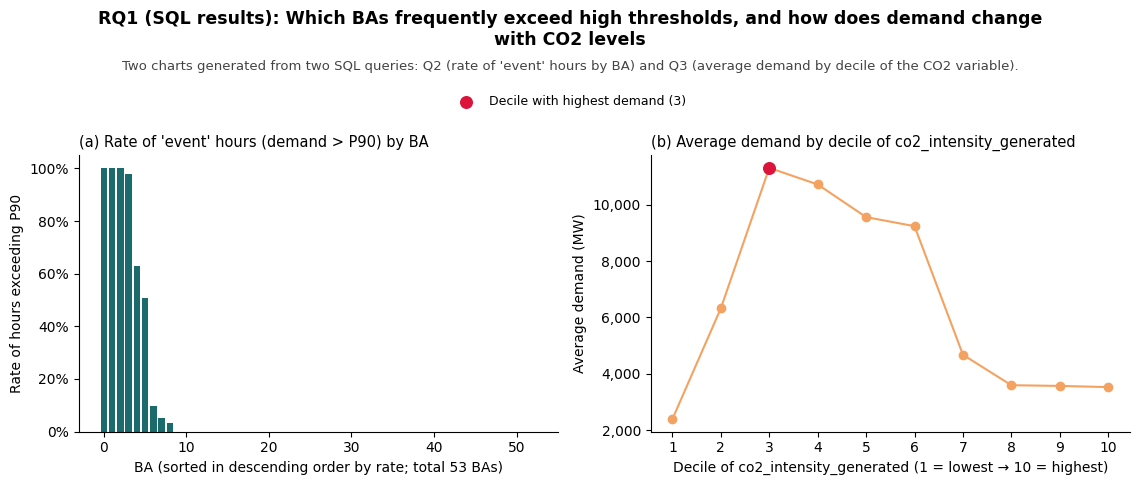

In [38]:
#Cell 3f — Hai hình RQ1 dựng từ kết quả SQL (event share theo BA, target theo decile CO2)
q2 = pd.read_csv("report/table_q2.csv")
q3 = pd.read_csv("report/table_q3.csv")
cov0 = EXOG_COLS[0]
P = int(round(EVENT_QUANTILE * 100))
n_units, n_any, n_half = len(q2), int((q2.event_share > 0).sum()), int((q2.event_share >= 0.5).sum())
pk = q3.loc[q3.mean_target.idxmax()]; last = q3.iloc[-1]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
axes[0].bar(range(len(q2)), q2.event_share, color=TEAL)
axes[0].set_title(f"(a) Rate of 'event' hours (demand > P{P}) by BA", fontsize=10.5, loc="left")
axes[0].set_xlabel(f"BA (sorted in descending order by rate; total {n_units} BAs)"); axes[0].set_ylabel(f"Rate of hours exceeding P{P}")
axes[0].set_ylim(0, 1.05); axes[0].yaxis.set_major_formatter(fmt_pct); style(axes[0])

axes[1].plot(q3.decile, q3.mean_target, marker="o", color=ACC)
axes[1].scatter([pk.decile], [pk.mean_target], color="crimson", s=70, zorder=5, label=f"Decile with highest demand ({int(pk.decile)})")
axes[1].set_title(f"(b) Average demand by decile of {cov0}", fontsize=10.5, loc="left")
axes[1].set_xticks(q3.decile)
axes[1].set_xlabel(f"Decile of {cov0} (1 = lowest → {int(last.decile)} = highest)"); axes[1].set_ylabel("Average demand (MW)")
axes[1].yaxis.set_major_formatter(fmt_int); style(axes[1])

savefig_annotated(
    fig, "fig_rq1_sql",
    title="RQ1 (SQL results): Which BAs frequently exceed high thresholds, and how does demand change with CO2 levels",
    subtitle="Two charts generated from two SQL queries: Q2 (rate of 'event' hours by BA) and Q3 (average demand by decile of the CO2 variable).",
    
    legend_from=axes[1], legend_ncol=1,
)

In [39]:
#Cell kiểm tra trước bàn giao
assert feat[[UNIT_COL, TIME_COL]].duplicated().sum() == 0, "trung lap unit-time"
assert feat[TARGET_COL].notna().all(), "target con thieu sau lam sach"
assert set(HORIZONS) <= set(int(c[3:]) for c in feat.columns if c.startswith("y_h")), "thieu cot target theo horizon"
assert (feat.groupby(UNIT_COL)[TIME_COL].apply(lambda s: s.is_monotonic_increasing)).all(), "thoi gian khong sap xep tang dan trong tung don vi"
assert len(feat) >= 30000, f"chi co {len(feat)} dong: can thu thap them du lieu hoac giam FREQ"
print("Test Buoc 3: OK")

Test Buoc 3: OK


In [40]:
#Cell bàn giao — lưu feat.parquet + manifest.json
import hashlib

feat.to_parquet("data/processed/feat.parquet", index=False)
feat.to_csv("data/processed/feat.csv", index=False)

md5 = hashlib.md5(open("data/processed/feat.parquet", "rb").read()).hexdigest()

manifest = {
    "group": GROUP, "topic": TOPIC, "rows": len(feat), "cols": list(feat.columns),
    "units": int(feat[UNIT_COL].nunique()), "start": str(feat[TIME_COL].min()), "end": str(feat[TIME_COL].max()),
    "freq": FREQ, "horizons": HORIZONS, "season": SEASON, "unit_col": UNIT_COL, "time_col": TIME_COL,
    "target_col": TARGET_COL, "exog_cols": [c for c in EXOG_COLS if c in feat.columns],
    "test_start": TEST_START, "md5": md5,
}
json.dump(manifest, open("data/processed/manifest.json", "w"), indent=2)
print(json.dumps(manifest, indent=2)[:600])

{
  "group": "Nhom 9",
  "topic": "Hourly Electricity Demand and Grid CO2 Emission Forecasting from EIA-930 Data with Global Gradient Boosting against the Official Day-ahead Forecast on Extreme Days",
  "rows": 1391895,
  "cols": [
    "ba",
    "ts_utc",
    "demand",
    "eia_fc",
    "co2_intensity_generated",
    "co2_intensity_consumed",
    "hr",
    "dow",
    "mon",
    "doy",
    "y_lag1",
    "y_lag2",
    "y_lag3",
    "y_lag24",
    "y_lag48",
    "y_lag168",
    "y_ma_season",
    "y_sd_season",
    "y_diff1",
    "co2_intensity_generated_lag_season",
    "co2_intensity_consumed_l
